# Preproduce VietASR

Bài báo: [`VietASR: Achieving Industry-level Vietnamese ASR with 50-hour labeled data and Large-Scale Speech Pretraining`](https://arxiv.org/pdf/2505.21527)  
Bộ dataset: [`nguyenvulebinh/ViCocktail`](https://huggingface.co/datasets/nguyenvulebinh/ViCocktail)  

## Notebook

0. Cấu hình
1. Chuẩn bị dữ liệu
2. Chạy **Pipeline VietASR** và **chuỗi HuBERT đối chứng**
Thử fine-tune bằng toàn bộ ~260 giờ có nhãn để (chạy ở cuối mỗi chuỗi | gộp bước 2)
3. Trực quan các bước + đánh giá mô hình
4. Export best model
5. So sánh với bài báo

## Pipeline chính của VietASR (4 giai đoạn, lặp nhiều vòng)

1. **S1 ASR**: học nhận dạng giọng nói chỉ từ dữ liệu có nhãn (ít samples hơn so với bài báo).
2. **S2 Tạo nhãn giả**: cho 150 giờ audio *không nhãn* chạy qua encoder của mô hình ASR, gom các vector lớp cuối thành 500 cụm (k-means). Mỗi khung 40 ms được gán số hiệu cụm cho "âm vị gần đúng"
3. **S3 Pre-train**: che ngẫu nhiên các đoạn Fbank và cho mô hình **đoán số hiệu cụm** chỗ che (học từ audio không nhãn).
4. **S4 Fine-tune**: dạy mô hình mới nhận dạng chữ bằng dữ liệu có nhãn -> Encoder tốt hơn -> lặp lại từ S2 để có nhãn giả tốt hơn

**HuBERT**: tương tự bài báo / nhãn giả vòng 1 lấy bằng k-means thẳng trên Fbank (không dùngASR) (Bài báo cho thấy nhãn "thiên về ASR" thắng)

## 0. Cấu hình

In [1]:
import os, sys, json, time, subprocess, shutil, math, glob, shlex, re, urllib.request
from pathlib import Path
T_START = time.time()
elapsed = lambda: f"{(time.time()-T_START)/60:6.1f} min"
import torch

# ============================== CONFIG ==============================
LAB_HOURS, UNL_HOURS, FULL_HOURS, DEV_UTTS = 50, 150, 300, 400   # bài báo: 50 h có nhãn / 70 000 h không nhãn
BPE_VOCAB, N_CLUSTERS = 500, 500                                 # đúng như bài báo
MODEL = dict(d=256, layers=8, heads=4, ff=1024)                  # ~13M tham số (bài báo: Zipformer 68M)
# phút GPU cho từng giai đoạn (khi có 2 GPU)
BUDGET = dict(scratch=55, pre1=90, ft1=45, pre2=130, ft2=45, full=75)
RUN_WHISPER = True                                               # mốc so sánh ngoài (chạy cuối cùng, ~15 phút)
WHISPER_SETS = ["test", "test_snr_10_interferer_1"]
# ====================================================================

N_GPU = torch.cuda.device_count()
assert N_GPU >= 1, "No GPU"
SCALE = 1.0 if N_GPU >= 2 else 0.45 
BUD = {k: max(5, int(v * SCALE)) for k, v in BUDGET.items()}

OUT = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("vietasr_out")
WORK = Path("/kaggle/temp/vietasr") if Path("/kaggle/temp").exists() else Path("/tmp/vietasr")
EXP, RES, LOGS = OUT / "exp", OUT / "results", OUT / "logs"
for p in (OUT, WORK, EXP, RES, LOGS):
    p.mkdir(parents=True, exist_ok=True)

print("GPUs:", [torch.cuda.get_device_name(i) for i in range(N_GPU)], "| ngân sách (phút):", BUD)
print("ổ đĩa trống work/out (GB):", round(shutil.disk_usage(WORK).free / 1e9), round(shutil.disk_usage(OUT).free / 1e9))
try:
    urllib.request.urlopen("https://huggingface.co", timeout=10)
    print("internet: OK")
except Exception as e:
    print("!!! Không truy cập được huggingface.co - bật Internet ở Settings:", e)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "av", "sentencepiece"], check=True)
import datasets; print("datasets", datasets.__version__)

GPUs: ['Tesla T4', 'Tesla T4'] | ngân sách (phút): {'scratch': 55, 'pre1': 90, 'ft1': 45, 'pre2': 130, 'ft2': 45, 'full': 75}
ổ đĩa trống work/out (GB): 2698 21
internet: OK
datasets 4.8.5


In [2]:
%%writefile vietasr_mini.py
#!/usr/bin/env python3
"""
vietasr_mini.py  -  compact, plain-PyTorch re-implementation of the VietASR recipe
(Zhuo et al., Interspeech 2025, arXiv:2505.21527) that fits on a Kaggle 2xT4 / 12h budget.

Pipeline (same 4 stages as the paper, see Fig.1 of the paper):
  Stage 1  initial ASR on a SMALL labelled set                       -> `train-asr`
  Stage 2  k-means on the final-layer encoder features -> labels      -> `kmeans`
  Stage 3  HuBERT-style masked prediction on UNLABELLED audio (CE)    -> `pretrain`
  Stage 4  fine-tune the pre-trained encoder on the small labelled set -> `finetune`
  Iteration n+1 restarts at Stage 2 using the fine-tuned encoder of iteration n.

Differences w.r.t. the original code base (icefall/k2 + Zipformer + pruned RNN-T), on purpose:
  * encoder: Conformer (pre-norm, macaron FFN, relative-free abs. sin PE), ~14M params instead of
    Zipformer-base 68M  -> pure PyTorch, no k2/icefall install on Kaggle
  * fine-tuning loss: CTC instead of pruned RNN-T
  * AdamW + time-based cosine schedule instead of ScaledAdam + Eden
  * data: ~50h labelled / ~150h unlabelled from ViCocktail instead of 50h / 70,000h YouTube
v2 additions (all aimed at making the weak/first model converge and the demo model accurate):
  * per-clip loudness normalisation inside `fbank` (recordings of any volume look alike)
  * CTC training aids: intermediate-CTC loss, EMA weights, length curriculum in epoch 0,
    automatic retry with a lower LR when the model collapses (dev WER > --max-ok-wer)
  * k-means guard: refuse a collapsed codebook (perplexity < --min-perplexity) instead of wasting hours
  * `full` store (all labelled train hours) for a *bonus* demo fine-tune, and `samples` command that exports demo clips
Everything that defines VietASR (Fbank front-end, masking on Fbank, CE loss on cluster ids,
ASR-biased codebook from a weak supervised model, multi-iteration) is kept.

CLI:  python vietasr_mini.py <prep|train-asr|finetune|kmeans|pretrain|eval|export|samples> ...
"""
from __future__ import annotations

import argparse
import collections
import copy
import io
import json
import math
import random
import re
import time
import unicodedata
import zlib
from collections import deque
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SR = 16000
N_MELS = 80
REPO = "nguyenvulebinh/ViCocktail"
TEST_SETS = ["test"] + [f"test_snr_{s}_interferer_{k}" for s in ("n5", "0", "5", "10") for k in (1, 2)]


# ----------------------------------------------------------------------------------------------
# text / audio utilities
# ----------------------------------------------------------------------------------------------
_NON_WORD = re.compile(r"[^\w\s]|_", re.UNICODE)


def norm_text(s: str) -> str:
    """lower-case, NFC, strip punctuation -> space separated Vietnamese syllables."""
    s = unicodedata.normalize("NFC", s).lower()
    s = _NON_WORD.sub(" ", s)
    return re.sub(r"\s+", " ", s).strip()


def to_text(x) -> str:
    if x is None:
        return ""
    if isinstance(x, str):
        return x
    if isinstance(x, (bytes, bytearray)):
        return bytes(x).decode("utf-8", "ignore")
    if isinstance(x, (list, tuple)):
        return bytes(x).decode("utf-8", "ignore")
    return str(x)


def to_bytes(x) -> bytes:
    if isinstance(x, dict):
        x = x.get("bytes", None)
    if isinstance(x, (bytes, bytearray)):
        return bytes(x)
    if isinstance(x, (list, tuple)):
        return bytes(x)
    raise TypeError(f"cannot turn {type(x)} into bytes (is the 'video' column decoded by `datasets`?)")


def _as_list(x):
    if x is None:
        return []
    return x if isinstance(x, (list, tuple)) else [x]


def decode_audio(b: bytes, sr: int = SR) -> np.ndarray:
    """Decode the audio track of an mp4/any container held in memory -> float32 mono @ sr (PyAV)."""
    import av

    out = []
    with av.open(io.BytesIO(b)) as c:
        if not c.streams.audio:
            return np.zeros(0, np.float32)
        rs = av.AudioResampler(format="s16", layout="mono", rate=sr)
        for fr in c.decode(audio=0):
            for r in _as_list(rs.resample(fr)):
                out.append(r.to_ndarray().reshape(-1))
        for r in _as_list(rs.resample(None)):
            out.append(r.to_ndarray().reshape(-1))
    if not out:
        return np.zeros(0, np.float32)
    return np.concatenate(out).astype(np.float32) / 32768.0


def load_audio_file(path: str, sr: int = SR) -> np.ndarray:
    """Any audio/video file -> float32 mono @ sr using the ffmpeg binary."""
    import shutil
    import subprocess

    exe = shutil.which("ffmpeg")
    if exe is None:
        try:
            import imageio_ffmpeg

            exe = imageio_ffmpeg.get_ffmpeg_exe()
        except Exception as e:  # pragma: no cover
            raise RuntimeError("ffmpeg not found (install ffmpeg or `pip install imageio-ffmpeg`)") from e
    cmd = [exe, "-nostdin", "-v", "error", "-i", path, "-vn", "-ac", "1", "-ar", str(sr), "-f", "s16le", "-"]
    p = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    if p.returncode != 0 or not p.stdout:
        raise RuntimeError("ffmpeg failed: " + p.stderr.decode("utf-8", "ignore")[-400:])
    return np.frombuffer(p.stdout, dtype=np.int16).astype(np.float32) / 32768.0


_MEL = {}


def _mel_filterbank(n_fft=512, n_mels=N_MELS, sr=SR, fmin=20.0, fmax=8000.0) -> torch.Tensor:
    key = (n_fft, n_mels, sr, fmin, fmax)
    if key not in _MEL:
        hz2mel = lambda f: 2595.0 * np.log10(1.0 + f / 700.0)
        mel2hz = lambda m: 700.0 * (10.0 ** (m / 2595.0) - 1.0)
        pts = mel2hz(np.linspace(hz2mel(fmin), hz2mel(fmax), n_mels + 2))
        bins = np.fft.rfftfreq(n_fft, 1.0 / sr)
        fb = np.zeros((n_mels, n_fft // 2 + 1), np.float32)
        for i in range(n_mels):
            lo, c, hi = pts[i], pts[i + 1], pts[i + 2]
            fb[i] = np.maximum(0.0, np.minimum((bins - lo) / (c - lo), (hi - bins) / (hi - c)))
        _MEL[key] = torch.from_numpy(fb)
    return _MEL[key]


def level_norm(w, target=0.06):
    """Scale a waveform so that its *speech* level (mean power of the louder half of the 25 ms frames)
    has RMS = target.  Makes quiet phone recordings and loud studio audio look alike to the model."""
    n = (w.numel() // 400) * 400
    if n < 400:
        return w
    ms = (w[:n].reshape(-1, 400) ** 2).mean(1)
    loud = ms[ms >= ms.median()]
    rms = float(loud.mean().sqrt())
    if rms < 1e-5:
        return w
    return w * min(max(target / rms, 0.05), 100.0)


def fbank(wave, level=True) -> torch.Tensor:
    """80-dim log-mel Fbank, 25 ms window / 10 ms shift  ->  [T, 80] float32 (T = 1 + (L-400)//160)."""
    w = torch.as_tensor(wave, dtype=torch.float32).reshape(-1)
    if level:
        w = level_norm(w)
    if w.numel() < 400:
        w = F.pad(w, (0, 400 - w.numel()))
    win = torch.hann_window(400)
    spec = torch.stft(w, n_fft=512, hop_length=160, win_length=400, window=win, center=False, return_complex=True)
    mel = _mel_filterbank() @ (spec.abs() ** 2)
    return torch.log(mel.clamp(min=1e-7)).transpose(0, 1).contiguous()


def sub_len(n):
    """#frames after the 4x Conv2d subsampling (== avg_pool1d(kernel=7, stride=4) length)."""
    return ((n - 1) // 2 - 1) // 2


# ----------------------------------------------------------------------------------------------
# WER
# ----------------------------------------------------------------------------------------------
def edit_distance(a, b):
    if not a:
        return len(b)
    if not b:
        return len(a)
    prev = list(range(len(b) + 1))
    for i, x in enumerate(a, 1):
        cur = [i] + [0] * len(b)
        for j, y in enumerate(b, 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (x != y))
        prev = cur
    return prev[-1]


def wer_corpus(refs, hyps):
    errs = n = 0
    for r, h in zip(refs, hyps, strict=True):
        rw, hw = r.split(), h.split()
        errs += edit_distance(rw, hw)
        n += len(rw)
    return 100.0 * errs / max(n, 1), n


# ----------------------------------------------------------------------------------------------
# feature stores (flat fp16 memmap + json index)
# ----------------------------------------------------------------------------------------------
class StoreWriter:
    def __init__(self, prefix, keep_wave=False):
        self.prefix = str(prefix)
        Path(self.prefix).parent.mkdir(parents=True, exist_ok=True)
        self.fb = open(self.prefix + ".bin", "wb")
        self.wf = open(self.prefix + ".wav16", "wb") if keep_wave else None
        self.items, self.off, self.woff = [], 0, 0

    def add(self, uid, text, feats: np.ndarray, wave: np.ndarray | None = None):
        feats = np.ascontiguousarray(feats, dtype=np.float16)
        it = {"id": uid, "off": self.off, "n": int(feats.shape[0])}
        if text is not None:
            it["text"] = text
        self.fb.write(feats.tobytes())
        self.off += feats.shape[0]
        if self.wf is not None and wave is not None:
            wave = np.ascontiguousarray(wave, dtype=np.int16)
            self.wf.write(wave.tobytes())
            it["woff"], it["wn"] = self.woff, int(wave.size)
            self.woff += wave.size
        self.items.append(it)

    @property
    def hours(self):
        return self.off / 100.0 / 3600.0

    def close(self):
        self.fb.close()
        if self.wf is not None:
            self.wf.close()
        json.dump({"items": self.items, "n_mels": N_MELS}, open(self.prefix + ".json", "w"), ensure_ascii=False)


class Store:
    def __init__(self, prefix):
        self.prefix = str(prefix)
        self.items = json.load(open(self.prefix + ".json"))["items"]
        self.lens = [it["n"] for it in self.items]
        self._mm = None
        self._wm = None

    def __len__(self):
        return len(self.items)

    @property
    def hours(self):
        return sum(self.lens) / 100.0 / 3600.0

    def get(self, i) -> np.ndarray:
        if self._mm is None:
            self._mm = np.memmap(self.prefix + ".bin", dtype=np.float16, mode="r").reshape(-1, N_MELS)
        it = self.items[i]
        return np.asarray(self._mm[it["off"]: it["off"] + it["n"]])

    def wave(self, i) -> np.ndarray:
        if self._wm is None:
            self._wm = np.memmap(self.prefix + ".wav16", dtype=np.int16, mode="r")
        it = self.items[i]
        return np.asarray(self._wm[it["woff"]: it["woff"] + it["wn"]]).astype(np.float32) / 32768.0

    def texts(self):
        return [it.get("text", "") for it in self.items]


class LabelStore:
    """k-means cluster ids per output frame, aligned with a Store (same item order)."""

    def __init__(self, prefix):
        self.prefix = str(prefix)
        m = json.load(open(self.prefix + ".json"))
        self.offs, self.lens, self.k = m["offs"], m["lens"], m["k"]
        self._mm = None

    def get(self, i):
        if self._mm is None:
            self._mm = np.memmap(self.prefix + ".bin", dtype=np.int16, mode="r")
        return np.asarray(self._mm[self.offs[i]: self.offs[i] + self.lens[i]]).astype(np.int64)


def load_stats(work):
    s = json.load(open(Path(work) / "stats.json"))
    return np.array(s["mean"], np.float32), np.array(s["std"], np.float32)


def make_batches(lens, max_frames, shuffle, seed, min_len=0, max_len=10 ** 9, ok=None, curriculum=False):
    """Length-bucketed batches.  curriculum=True: shortest utterances first, batches in that order
    (an 'epoch 0' warm-up that makes CTC from scratch escape the all-blank plateau)."""
    idx = [i for i, l in enumerate(lens) if min_len <= l <= max_len and (ok is None or ok[i])]
    rng = random.Random(seed)
    if curriculum:
        shuffle = False
    jitter = {i: lens[i] * (1.0 + (rng.uniform(-0.1, 0.1) if shuffle else 0.0)) for i in idx}
    idx.sort(key=lambda i: jitter[i])
    batches, cur, mx = [], [], 0
    for i in idx:
        L = lens[i]
        if cur and max(mx, L) * (len(cur) + 1) > max_frames:
            batches.append(cur)
            cur, mx = [], 0
        cur.append(i)
        mx = max(mx, L)
    if cur:
        batches.append(cur)
    if shuffle:
        rng.shuffle(batches)
    return batches


class BatchDS(torch.utils.data.Dataset):
    """Each item is a fully collated batch (use DataLoader(batch_size=None))."""

    def __init__(self, store, batches, stats, tokens=None, labels=None):
        self.store, self.batches, self.tokens, self.labels = store, batches, tokens, labels
        self.mean, self.std = stats

    def __len__(self):
        return len(self.batches)

    def __getitem__(self, bi):
        idxs = self.batches[bi]
        arrs = [(self.store.get(i).astype(np.float32) - self.mean) / self.std for i in idxs]
        lens = np.array([a.shape[0] for a in arrs], np.int64)
        x = np.zeros((len(arrs), int(lens.max()), N_MELS), np.float16)
        for k, a in enumerate(arrs):
            x[k, : a.shape[0]] = a
        out = {"x": torch.from_numpy(x), "lens": torch.from_numpy(lens), "idx": torch.tensor(idxs)}
        if self.tokens is not None:
            ys = [self.tokens[i] for i in idxs]
            out["y"] = torch.from_numpy(np.concatenate(ys).astype(np.int64))
            out["ylens"] = torch.tensor([len(y) for y in ys], dtype=torch.int64)
        if self.labels is not None:
            zs = [self.labels.get(i) for i in idxs]
            tp = int(sub_len(lens.max()))
            z = np.full((len(zs), tp), -100, np.int64)
            for k, a in enumerate(zs):
                z[k, : a.shape[0]] = a
            out["z"] = torch.from_numpy(z)
        return out


def make_loader(ds, workers):
    return torch.utils.data.DataLoader(
        ds, batch_size=None, shuffle=False, num_workers=workers,
        pin_memory=torch.cuda.is_available(), prefetch_factor=4 if workers > 0 else None,
    )


# ----------------------------------------------------------------------------------------------
# model: Fbank -> Conv2d/4 -> N x Conformer block ;  heads: cls_head (SSL) / ctc_head (ASR)
# ----------------------------------------------------------------------------------------------
class Conv2dSub(nn.Module):
    def __init__(self, idim, odim, ch=64):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(1, ch, 3, 2), nn.ReLU(), nn.Conv2d(ch, ch, 3, 2), nn.ReLU())
        self.out = nn.Linear(ch * (((idim - 1) // 2 - 1) // 2), odim)

    def forward(self, x):
        x = self.conv(x.unsqueeze(1))
        b, c, t, f = x.shape
        return self.out(x.permute(0, 2, 1, 3).reshape(b, t, c * f))


class FFN(nn.Module):
    def __init__(self, d, ff, drop):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, ff), nn.SiLU(), nn.Dropout(drop), nn.Linear(ff, d), nn.Dropout(drop))

    def forward(self, x):
        return self.net(x)


class MHSA(nn.Module):
    def __init__(self, d, h, drop):
        super().__init__()
        self.h, self.drop = h, drop
        self.qkv, self.o = nn.Linear(d, 3 * d), nn.Linear(d, d)

    def forward(self, x, pad):
        B, T, D = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=(~pad)[:, None, None, :],
                                           dropout_p=self.drop if self.training else 0.0)
        return self.o(y.transpose(1, 2).reshape(B, T, D))


class ConvMod(nn.Module):
    def __init__(self, d, k, drop):
        super().__init__()
        self.ln = nn.LayerNorm(d)
        self.pw1 = nn.Conv1d(d, 2 * d, 1)
        self.dw = nn.Conv1d(d, d, k, padding=k // 2, groups=d)
        self.ln2 = nn.LayerNorm(d)
        self.pw2 = nn.Conv1d(d, d, 1)
        self.drop = nn.Dropout(drop)

    def forward(self, x, pad):
        y = self.ln(x).masked_fill(pad.unsqueeze(-1), 0.0).transpose(1, 2)
        y = F.glu(self.pw1(y), dim=1)
        y = self.dw(y).transpose(1, 2)
        y = F.silu(self.ln2(y)).transpose(1, 2)
        return self.drop(self.pw2(y).transpose(1, 2))


class Block(nn.Module):
    def __init__(self, d, h, ff, k, drop):
        super().__init__()
        self.ff1, self.ff2 = FFN(d, ff, drop), FFN(d, ff, drop)
        self.ln_att, self.att = nn.LayerNorm(d), MHSA(d, h, drop)
        self.conv, self.ln, self.drop = ConvMod(d, k, drop), nn.LayerNorm(d), nn.Dropout(drop)

    def forward(self, x, pad):
        x = x + 0.5 * self.ff1(x)
        x = x + self.drop(self.att(self.ln_att(x), pad))
        x = x + self.conv(x, pad)
        x = x + 0.5 * self.ff2(x)
        return self.ln(x)


class AcousticModel(nn.Module):
    def __init__(self, d=256, heads=4, ff=1024, layers=8, kernel=31, drop=0.1, n_cls=500, vocab=256, max_len=4000):
        super().__init__()
        self.cfg = dict(d=d, heads=heads, ff=ff, layers=layers, kernel=kernel, drop=drop, n_cls=n_cls, vocab=vocab, max_len=max_len)
        self.d = d
        self.sub = Conv2dSub(N_MELS, d)
        self.blocks = nn.ModuleList([Block(d, heads, ff, kernel, drop) for _ in range(layers)])
        self.mask_emb = nn.Parameter(torch.zeros(N_MELS))
        self.drop = nn.Dropout(drop)
        self.cls_head = nn.Linear(d, n_cls)
        self.ctc_head = nn.Linear(d, vocab)
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
        pe = torch.zeros(max_len, d)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe, persistent=False)

    def encode(self, x, lens, mask=None, layer=None, collect=None):
        """x [B,T,80] (normalised), lens [B]; mask [B,T] bool (True = replace frame by mask_emb).
        collect=i : remember the output of block i in self.mid (used by the intermediate-CTC loss)."""
        if mask is not None:
            x = torch.where(mask.unsqueeze(-1), self.mask_emb.to(x.dtype), x)
        h = self.sub(x)
        hl = sub_len(lens)
        T = h.size(1)
        h = self.drop(h * math.sqrt(self.d) + self.pe[:T].to(h.dtype))
        pad = torch.arange(T, device=h.device)[None, :] >= hl[:, None]
        self.mid = None
        for i, b in enumerate(self.blocks):
            h = b(h, pad)
            if collect is not None and i == collect:
                self.mid = h
            if layer is not None and i == layer:
                break
        return h, hl


def count_params(m):
    return sum(p.numel() for p in m.parameters())


def save_ckpt(path, model, **extra):
    torch.save({"model": model.state_dict(), "cfg": model.cfg, **extra}, path)


def load_model(path, device="cpu"):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    m = AcousticModel(**ck["cfg"])
    m.load_state_dict(ck["model"])
    return m.to(device).eval(), ck


# ----------------------------------------------------------------------------------------------
# augmentation / masking
# ----------------------------------------------------------------------------------------------
def spec_augment(x, lens, n_freq=2, f_max=27, n_time=3, t_max=40):
    B, T, Fd = x.shape
    dev = x.device
    x = x.clone()
    ar_f = torch.arange(Fd, device=dev)[None, None, :]
    for _ in range(n_freq):
        w = torch.randint(0, f_max + 1, (B, 1, 1), device=dev)
        s = (torch.rand(B, 1, 1, device=dev) * (Fd - w)).long()
        x = x.masked_fill((ar_f >= s) & (ar_f < s + w), 0.0)
    ar_t = torch.arange(T, device=dev)[None, :, None]
    for _ in range(n_time):
        wmax = torch.clamp((lens.float() * 0.1), max=t_max).long()
        w = (torch.rand(B, device=dev) * (wmax + 1)).long()
        s = (torch.rand(B, device=dev) * (lens - w).clamp(min=1)).long()
        x = x.masked_fill((ar_t >= s[:, None, None]) & (ar_t < (s + w)[:, None, None]), 0.0)
    return x


def make_mask(lens, T, prob, span):
    """HuBERT-style span mask applied on Fbank frames: each frame starts a span w.p. `prob`."""
    dev = lens.device
    valid = torch.arange(T, device=dev)[None, :] < lens[:, None]
    starts = ((torch.rand(len(lens), T, device=dev) < prob) & valid).float()[:, None]
    m = F.max_pool1d(F.pad(starts, (span - 1, 0)), kernel_size=span, stride=1)[:, 0] > 0
    return m & valid


# ----------------------------------------------------------------------------------------------
# decoding
# ----------------------------------------------------------------------------------------------
def ctc_collapse(ids):
    out, prev = [], -1
    for t in ids:
        if t != prev and t != 0:
            out.append(int(t))
        prev = t
    return out


@torch.no_grad()
def decode_store(model, store, sp, stats, idx=None, max_frames=300000, workers=0, return_time=False):
    dev = next(model.parameters()).device
    model.eval()
    idx = list(range(len(store))) if idx is None else list(idx)
    lens = [store.lens[i] for i in idx]
    sub_batches = make_batches(lens, max_frames, False, 0)
    ds = BatchDS(store, [[idx[j] for j in b] for b in sub_batches], stats)
    hyps, tsum = {}, 0.0
    for batch in make_loader(ds, workers):
        x, l = batch["x"].to(dev).float(), batch["lens"].to(dev)
        if dev.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.time()
        with torch.autocast(dev.type, dtype=torch.float16, enabled=dev.type == "cuda"):
            h, hl = model.encode(x, l)
            lg = model.ctc_head(h)
        am = lg.argmax(-1).cpu().numpy()
        if dev.type == "cuda":
            torch.cuda.synchronize()
        tsum += time.time() - t0
        hl = hl.cpu().numpy()
        for k, i in enumerate(batch["idx"].tolist()):
            hyps[i] = norm_text(sp.decode(ctc_collapse(am[k, : hl[k]])))
    out = [hyps[i] for i in idx]
    return (out, tsum) if return_time else out


# ----------------------------------------------------------------------------------------------
# training loop (time-budgeted, resumable)
# ----------------------------------------------------------------------------------------------
def lr_at(frac, peak, warm=0.08, floor=0.02):
    if frac < warm:
        return peak * max(frac / warm, 0.02)
    p = (frac - warm) / (1 - warm)
    return peak * (floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * min(p, 1.0))))


def _swap(model, vals):
    """put `vals` (list of tensors) into the model parameters, return the previous values"""
    plist = list(model.parameters())
    old = [p.detach().clone() for p in plist]
    with torch.no_grad():
        for p, v in zip(plist, vals):
            p.copy_(v)
    return old


def train_loop(model, loader_fn, loss_fn, args, outdir, peak_lr, warm=0.08, freeze_frac=0.0, dev_eval=None, ema_decay=0.0):
    """Time-budgeted, resumable training.  ema_decay>0 keeps an exponential moving average of the weights;
    dev evaluations and the final model use the averaged weights (usually a few % relative WER better)."""
    outdir = Path(outdir)
    outdir.mkdir(parents=True, exist_ok=True)
    dev = next(model.parameters()).device
    cuda = dev.type == "cuda"
    plist = list(model.parameters())
    ema = [p.detach().clone() for p in plist] if ema_decay > 0 else None
    opt = torch.optim.AdamW(model.parameters(), lr=peak_lr, betas=(0.9, 0.98), weight_decay=args.wd)
    scaler = torch.amp.GradScaler("cuda", enabled=cuda)
    budget = args.minutes * 60.0
    elapsed0, step, epoch = 0.0, 0, 0
    last = outdir / "last.pt"
    if args.force and last.exists():
        last.unlink()
    resumed = last.exists()
    if resumed:
        ck = torch.load(last, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"])
        opt.load_state_dict(ck["opt"])
        if ema is not None and ck.get("ema") is not None:
            ema = [e.to(dev) for e in ck["ema"]]
        elapsed0, step, epoch = ck["elapsed"], ck["step"], ck["epoch"]
        print(f"[resume] {last} at {elapsed0/60:.1f} min, step {step}", flush=True)
    enc_params = [p for n, p in model.named_parameters() if not n.startswith(("ctc_head", "cls_head"))]
    logf = open(outdir / "log.jsonl", "a" if resumed else "w")
    t0 = time.time()
    last_save = last_eval = t0
    acc = collections.defaultdict(float)
    nacc = 0
    done = False
    model.train()
    while not done:
        got = 0
        for batch in loader_fn(epoch):
            got += 1
            el = elapsed0 + time.time() - t0
            frac = el / budget
            if frac >= 1.0:
                done = True
                break
            lr = lr_at(frac, peak_lr, warm)
            for g in opt.param_groups:
                g["lr"] = lr
            with torch.autocast(dev.type, dtype=torch.float16, enabled=cuda):
                loss, st = loss_fn(model, batch)
            if not torch.isfinite(loss):
                opt.zero_grad(set_to_none=True)
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            if frac < freeze_frac:
                for p in enc_params:
                    p.grad = None
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt)
            scaler.update()
            opt.zero_grad(set_to_none=True)
            step += 1
            nacc += 1
            if ema is not None:
                d = min(ema_decay, (1 + step) / (10 + step))
                torch._foreach_mul_(ema, d)
                torch._foreach_add_(ema, [p.detach() for p in plist], alpha=1 - d)
            acc["loss"] += float(loss)
            for k, v in st.items():
                acc[k] += float(v)
            if step % args.log_every == 0:
                rec = {"step": step, "epoch": epoch, "min": round(el / 60, 2), "lr": lr, "gn": float(gn)}
                rec.update({k: v / nacc for k, v in acc.items()})
                logf.write(json.dumps(rec) + "\n")
                logf.flush()
                print(" ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in rec.items()), flush=True)
                acc.clear()
                nacc = 0
            now = time.time()
            if dev_eval is not None and now - last_eval > args.eval_every * 60:
                backup = _swap(model, ema) if ema is not None else None
                w = dev_eval(model)
                if backup is not None:
                    _swap(model, backup)
                model.train()
                logf.write(json.dumps({"step": step, "min": round(el / 60, 2), "dev_wer": w}) + "\n")
                logf.flush()
                print(f"[dev] step {step} WER {w:.2f}", flush=True)
                last_eval = time.time()
            if now - last_save > 600:
                torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "elapsed": el, "step": step, "epoch": epoch,
                            "ema": ema}, last)
                last_save = now
        epoch += 1
        if got == 0:
            raise RuntimeError("data loader produced no batches (check filters / max-duration)")
    if ema is not None:
        _swap(model, ema)          # the averaged weights become the final model
    return step


# ----------------------------------------------------------------------------------------------
# losses
# ----------------------------------------------------------------------------------------------
def ctc_loss_fn(specaug, inter_weight=0.0):
    """CTC loss on the last layer (+ optional 'intermediate CTC' on the middle layer, same output head).
    The extra loss gives the lower layers a short gradient path, which is what lets a randomly
    initialised encoder leave the all-blank plateau."""
    def one(model, h, hl, batch, dev):
        lp = F.log_softmax(model.ctc_head(h).float(), -1).transpose(0, 1)
        loss = F.ctc_loss(lp, batch["y"].to(dev), hl, batch["ylens"].to(dev), blank=0, reduction="sum", zero_infinity=True)
        return loss / hl.sum()

    def fn(model, batch):
        dev = next(model.parameters()).device
        x, lens = batch["x"].to(dev, non_blocking=True).float(), batch["lens"].to(dev)
        if specaug:
            x = spec_augment(x, lens)
        mid = len(model.blocks) // 2 - 1
        h, hl = model.encode(x, lens, collect=mid if inter_weight > 0 else None)
        loss = one(model, h, hl, batch, dev)
        if inter_weight > 0 and model.mid is not None:
            loss = (1 - inter_weight) * loss + inter_weight * one(model, model.mid, hl, batch, dev)
        return loss, {}
    return fn


def pretrain_loss_fn(prob, span):
    def fn(model, batch):
        dev = next(model.parameters()).device
        x, lens, z = batch["x"].to(dev, non_blocking=True).float(), batch["lens"].to(dev), batch["z"].to(dev)
        m = make_mask(lens, x.size(1), prob, span)
        h, hl = model.encode(x, lens, mask=m)
        tp = h.size(1)
        sel = m[:, 3::4][:, :tp] & (z[:, :tp] != -100)
        if not bool(sel.any()):
            return h.sum() * 0.0, {}
        lg, tgt = model.cls_head(h)[sel].float(), z[:, :tp][sel]
        return F.cross_entropy(lg, tgt), {"acc": (lg.argmax(-1) == tgt).float().mean()}
    return fn


# ----------------------------------------------------------------------------------------------
# commands
# ----------------------------------------------------------------------------------------------
def _device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def _model_args(p):
    p.add_argument("--d", type=int, default=256)
    p.add_argument("--layers", type=int, default=8)
    p.add_argument("--heads", type=int, default=4)
    p.add_argument("--ff", type=int, default=1024)
    p.add_argument("--kernel", type=int, default=31)
    p.add_argument("--n-cls", type=int, default=500)


def _common(p):
    p.add_argument("--work", required=True, help="dir with the feature stores (stats.json, bpe.model, *.bin)")
    p.add_argument("--exp", required=True, help="dir for experiments")
    p.add_argument("--name", required=True)
    p.add_argument("--minutes", type=float, default=60)
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--wd", type=float, default=0.01)
    p.add_argument("--max-duration", type=float, default=600, help="seconds of (padded) audio per batch")
    p.add_argument("--workers", type=int, default=2)
    p.add_argument("--log-every", type=int, default=100)
    p.add_argument("--eval-every", type=float, default=15, help="minutes between dev-WER evaluations")
    p.add_argument("--dev-utts", type=int, default=300)
    p.add_argument("--force", action="store_true")
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--ema", type=float, default=0.0, help="EMA decay of the weights (0 = off)")
    p.add_argument("--train-store", default="lab", help="which labelled store to train on: lab | full")
    p.add_argument("--curriculum", action="store_true", help="epoch 0 = shortest utterances first")
    p.add_argument("--inter-weight", type=float, default=0.0, help="weight of the intermediate-CTC loss")
    p.add_argument("--warm", type=float, default=-1, help="warm-up fraction of the budget (-1 = default)")
    p.add_argument("--retries", type=int, default=0, help="retrain with lr*0.6 if dev WER > --max-ok-wer")
    p.add_argument("--max-ok-wer", type=float, default=0.0, help="0 = no collapse check")
    _model_args(p)


def _spm(work):
    import sentencepiece as spm

    return spm.SentencePieceProcessor(model_file=str(Path(work) / "bpe.model"))


def _new_model(a, sp):
    return AcousticModel(d=a.d, heads=a.heads, ff=a.ff, layers=a.layers, kernel=a.kernel, n_cls=a.n_cls, vocab=sp.get_piece_size())


def cmd_train_asr(a, finetune=False):
    out = Path(a.exp) / a.name
    if (out / "final.pt").exists() and not a.force:
        print(f"[skip] {out/'final.pt'} exists")
        return
    work = Path(a.work)
    sp, stats = _spm(work), load_stats(work)
    lab, devs = Store(work / a.train_store), Store(work / "dev")
    tokens = [np.array(sp.encode(t), np.int64) for t in lab.texts()]
    ok = [0 < len(tokens[i]) <= sub_len(lab.lens[i]) for i in range(len(lab))]
    dev_idx = list(range(min(a.dev_utts, len(devs))))
    dev = _device()

    def dev_eval(m):
        hy = decode_store(m, devs, sp, stats, dev_idx)
        return wer_corpus([devs.items[i]["text"] for i in dev_idx], hy)[0]

    final, model = None, None
    for attempt in range(a.retries + 1):
        run = copy.copy(a)
        run.lr = a.lr * (0.6 ** attempt)
        run.seed = a.seed + 17 * attempt
        if attempt > 0:
            run.force = True            # drop last.pt of the collapsed attempt
            print(f"[{a.name}] attempt {attempt}: previous dev WER {final:.1f}% -> retry with lr={run.lr:.2g}", flush=True)
        torch.manual_seed(run.seed)
        random.seed(run.seed)
        model = _new_model(a, sp)
        if finetune:
            ck = torch.load(a.init, map_location="cpu", weights_only=False)
            sd = {k: v for k, v in ck["model"].items() if not k.startswith("ctc_head")}
            print("[finetune] init from", a.init, model.load_state_dict(sd, strict=False))
        model.to(dev)
        print(f"[{a.name}] params={count_params(model)/1e6:.2f}M  train={a.train_store} {lab.hours:.1f}h  device={dev}  lr={run.lr:.2g}", flush=True)

        def loader_fn(epoch, run=run):
            b = make_batches(lab.lens, int(run.max_duration * 100), True, run.seed + epoch, 50, 3000, ok,
                             curriculum=run.curriculum and epoch == 0)
            return make_loader(BatchDS(lab, b, stats, tokens=tokens), run.workers)

        warm = a.warm if a.warm >= 0 else (0.1 if finetune else 0.15)
        train_loop(model, loader_fn, ctc_loss_fn(True, a.inter_weight), run, out, run.lr, warm=warm,
                   freeze_frac=a.freeze_frac if finetune else 0.0, dev_eval=dev_eval, ema_decay=a.ema)
        final = dev_eval(model)
        print(f"[{a.name}] final dev WER {final:.2f}", flush=True)
        if a.max_ok_wer <= 0 or final <= a.max_ok_wer:
            break
    if a.max_ok_wer > 0 and final > a.max_ok_wer:
        save_ckpt(out / "final_FAILED.pt", model, vocab=sp.get_piece_size(), dev_wer=final)
        raise RuntimeError(f"[{a.name}] did not converge (dev WER {final:.1f}% > {a.max_ok_wer}%) after {a.retries + 1} attempt(s)")
    save_ckpt(out / "final.pt", model, vocab=sp.get_piece_size(), dev_wer=final, stage="finetune" if finetune else "asr")


def cmd_pretrain(a):
    out = Path(a.exp) / a.name
    if (out / "final.pt").exists() and not a.force:
        print(f"[skip] {out/'final.pt'} exists")
        return
    torch.manual_seed(a.seed)
    dev = _device()
    work = Path(a.work)
    sp, stats = _spm(work), load_stats(work)
    unl = Store(work / "unl")
    labels = LabelStore(Path(a.work) / f"labels_{a.labels}")
    model = _new_model(a, sp).to(dev)
    print(f"[{a.name}] params={count_params(model)/1e6:.2f}M  unlabelled={unl.hours:.1f}h  labels={a.labels} (K={labels.k})", flush=True)

    def loader_fn(epoch):
        b = make_batches(unl.lens, int(a.max_duration * 100), True, a.seed + epoch, 100, 2000)
        return make_loader(BatchDS(unl, b, stats, labels=labels), a.workers)

    train_loop(model, loader_fn, pretrain_loss_fn(a.mask_prob, a.mask_span), a, out, a.lr, warm=0.08)
    save_ckpt(out / "final.pt", model, vocab=sp.get_piece_size(), stage="pretrain", labels=a.labels)


def kmeans_fit(X, k, iters=100, seed=0, tol=1e-4):
    g = torch.Generator(device=X.device).manual_seed(seed)
    N = X.size(0)
    C = X[torch.randperm(N, generator=g, device=X.device)[:k]].clone()
    for it in range(iters):
        sums, cnt = torch.zeros_like(C), torch.zeros(k, device=X.device)
        for ch in X.split(200000):
            a = kmeans_assign(C, ch)
            sums.index_add_(0, a, ch)
            cnt.index_add_(0, a, torch.ones_like(a, dtype=torch.float32))
        newC = sums / cnt.clamp(min=1)[:, None]
        empty = cnt == 0
        if bool(empty.any()):
            newC[empty] = X[torch.randint(0, N, (int(empty.sum()),), generator=g, device=X.device)]
        shift = float((newC - C).norm() / C.norm().clamp(min=1e-8))
        C = newC
        if it % 10 == 0:
            print(f"  kmeans iter {it} shift {shift:.5f} empty {int(empty.sum())}", flush=True)
        if shift < tol:
            break
    return C


def kmeans_assign(C, f):
    d = (f ** 2).sum(1, keepdim=True) - 2 * f @ C.t() + (C ** 2).sum(1)[None]
    return d.argmin(1)


@torch.no_grad()
def cmd_kmeans(a):
    """Fit k-means on frame features and write one cluster id per output frame for every unlabelled utt.
       --source fbank          : HuBERT iteration-1 codebook (k-means on 80-d Fbank, pooled to the encoder frame rate)
       --source <ckpt>         : features of an encoder; --layer -1 = final layer (VietASR), i>=0 = i-th block (HuBERT it>=2)
    """
    binp = Path(a.work) / f"labels_{a.out}.bin"
    if binp.exists() and not a.force:
        print(f"[skip] {binp} exists")
        return
    dev = _device()
    work = Path(a.work)
    stats = load_stats(work)
    unl = Store(work / "unl")
    model = None
    if a.source != "fbank":
        model, _ = load_model(a.source, dev)

    def feats(x, lens):
        x = x.to(dev).float()
        if model is None:
            return F.avg_pool1d(x.transpose(1, 2), kernel_size=7, stride=4).transpose(1, 2)
        with torch.autocast(dev.type, dtype=torch.float16, enabled=dev.type == "cuda"):
            h, _ = model.encode(x, lens.to(dev), layer=None if a.layer < 0 else a.layer)
        return h.float()

    # ---- pass 1: sample ~km_hours of frames and fit
    rng = random.Random(a.seed)
    order = list(range(len(unl)))
    rng.shuffle(order)
    pick, tot = [], 0.0
    for i in order:
        if tot >= a.km_hours:
            break
        pick.append(i)
        tot += unl.lens[i] / 360000.0
    local = make_batches([unl.lens[i] for i in pick], 300000, False, 0)
    ds = BatchDS(unl, [[pick[j] for j in b] for b in local], stats)
    chunks = []
    for b in make_loader(ds, 2):
        f = feats(b["x"], b["lens"])
        tl = sub_len(b["lens"])
        for k in range(f.size(0)):
            chunks.append(f[k, : int(tl[k])])
    X = torch.cat(chunks)
    print(f"[kmeans {a.out}] fitting K={a.k} on {X.size(0)} frames x {X.size(1)} dims ({tot:.1f} h)", flush=True)
    C = kmeans_fit(X, a.k, a.iters, a.seed)
    del X, chunks
    # ---- pass 2: label everything
    allb = make_batches(unl.lens, 300000, False, 0)
    ds = BatchDS(unl, allb, stats)
    offs, lens_out = [0] * len(unl), [0] * len(unl)
    hist = torch.zeros(a.k, device=dev)
    pos = 0
    with open(binp, "wb") as fo:
        res = {}
        for b in make_loader(ds, 2):
            f = feats(b["x"], b["lens"])
            tl = sub_len(b["lens"])
            for k, i in enumerate(b["idx"].tolist()):
                lab = kmeans_assign(C, f[k, : int(tl[k])]).to(torch.int16)
                hist += torch.bincount(lab.long(), minlength=a.k).float()
                res[i] = lab.cpu().numpy()
        for i in range(len(unl)):          # write in store order so offsets are monotone
            offs[i], lens_out[i] = pos, int(res[i].shape[0])
            res[i].tofile(fo)
            pos += lens_out[i]
    p = hist / hist.sum()
    ent = float(-(p[p > 0] * p[p > 0].log()).sum())
    if math.exp(ent) < a.min_perplexity:
        binp.unlink()
        raise RuntimeError(f"[kmeans {a.out}] codebook collapsed (perplexity {math.exp(ent):.1f} < {a.min_perplexity}): "
                           f"the source model '{a.source}' produces near-constant features, so these labels are useless for pre-training")
    json.dump({"offs": offs, "lens": lens_out, "k": a.k, "source": a.source, "layer": a.layer,
               "entropy_nats": ent, "perplexity": math.exp(ent), "used": int((hist > 0).sum()),
               "hist": hist.cpu().tolist()}, open(work / f"labels_{a.out}.json", "w"))
    torch.save(C.cpu(), work / f"centroids_{a.out}.pt")
    print(f"[kmeans {a.out}] done: {pos} labels, codebook perplexity {math.exp(ent):.1f} / {a.k}, used {int((hist>0).sum())}", flush=True)


def cmd_eval(a):
    dev = _device()
    work = Path(a.work)
    sp, stats = _spm(work), load_stats(work)
    model, ck = load_model(a.ckpt, dev)
    res = {"name": a.name or Path(a.ckpt).parent.name, "params_M": count_params(model) / 1e6, "wer": {}, "words": {}, "samples": {}}
    sets = ["dev"] + TEST_SETS
    tot_audio = tot_time = 0.0
    for s in sets:
        pf = work / (s if s == "dev" else f"test__{s}")
        if not Path(str(pf) + ".json").exists():
            continue
        st = Store(pf)
        hy, t = decode_store(model, st, sp, stats, return_time=True)
        refs = st.texts()
        w, n = wer_corpus(refs, hy)
        res["wer"][s], res["words"][s] = w, n
        res["samples"][s] = [{"ref": refs[i], "hyp": hy[i]} for i in range(min(8, len(refs)))]
        tot_audio += st.hours * 3600
        tot_time += t
        print(f"[eval {res['name']}] {s:28s} WER {w:6.2f}  ({n} words)", flush=True)
    res["rtf"] = tot_time / max(tot_audio, 1e-9)
    Path(a.out).parent.mkdir(parents=True, exist_ok=True)
    json.dump(res, open(a.out, "w"), ensure_ascii=False, indent=1)


def cmd_export(a):
    """Package a fine-tuned model for the Streamlit demo."""
    import shutil

    out = Path(a.out)
    out.mkdir(parents=True, exist_ok=True)
    ck = torch.load(a.ckpt, map_location="cpu", weights_only=False)
    sd = {k: v.half() if v.is_floating_point() else v for k, v in ck["model"].items()}
    torch.save({"model": sd, "cfg": ck["cfg"], "vocab": ck.get("vocab"), "level_norm": not a.no_level_norm}, out / "model.pt")
    shutil.copy(Path(a.work) / "bpe.model", out / "bpe.model")
    shutil.copy(Path(a.work) / "stats.json", out / "stats.json")
    meta = {"name": a.name, "clean_test_wer": a.wer if a.wer >= 0 else None, "note": a.note, "level_norm": not a.no_level_norm}
    json.dump(meta, open(out / "meta.json", "w"), ensure_ascii=False, indent=1)
    print("exported to", out)


# ---------------------------------------------------------------- data preparation (Kaggle)
def _init_worker():
    torch.set_num_threads(1)


def _decode_job(job):
    sid, label, vb, keep_wave = job
    try:
        wave = decode_audio(vb)
        if wave.size < 1600:
            return None
        return sid, label, fbank(wave).numpy().astype(np.float16), (np.clip(wave, -1, 1) * 32767).astype(np.int16) if keep_wave else None
    except Exception as e:  # corrupt clip -> skip
        print("decode error", sid, repr(e)[:100], flush=True)
        return None


def _pmap(pool, jobs, window=64):
    q = deque()
    for j in jobs:
        q.append(pool.apply_async(_decode_job, (j,)))
        if len(q) >= window:
            yield q.popleft().get()
    while q:
        yield q.popleft().get()


def _stream(split, seed=None, buffer=0, retries=6):
    from datasets import load_dataset

    consumed = 0
    for attempt in range(retries):
        try:
            ds = load_dataset(REPO, split=split, streaming=True)
            if buffer:
                ds = ds.shuffle(seed=seed, buffer_size=buffer)
            if consumed:
                ds = ds.skip(consumed)
            for ex in ds:
                consumed += 1
                yield ex
            return
        except Exception as e:
            print(f"[stream {split}] error after {consumed} samples: {repr(e)[:150]} - retry {attempt+1}/{retries}", flush=True)
            time.sleep(15)
    raise RuntimeError(f"stream {split} failed")


def _fields(ex):
    sid = to_text(ex.get("sample_id")) or to_text(ex.get("__key__"))
    if "video" not in ex or "label" not in ex:
        raise KeyError(f"unexpected columns: {list(ex.keys())}")
    return sid, norm_text(to_text(ex["label"])), to_bytes(ex["video"])


def _video_id(sid):
    m = re.split(r"_\d{5}_", sid)
    return m[0] if len(m) > 1 else sid[:11]


def train_bpe(texts, work, vocab):
    import sentencepiece as spm

    tf = Path(work) / "lab_text.txt"
    tf.write_text("\n".join(texts), encoding="utf-8")
    spm.SentencePieceTrainer.train(
        input=str(tf), model_prefix=str(Path(work) / "bpe"), vocab_size=vocab, model_type="bpe",
        character_coverage=1.0, pad_id=0, pad_piece="<blk>", unk_id=1, bos_id=-1, eos_id=-1,
        normalization_rule_name="identity", hard_vocab_limit=False, input_sentence_size=2000000, shuffle_input_sentence=True)


def compute_stats(work, n=3000):
    st = Store(Path(work) / "lab")
    sel = np.linspace(0, len(st) - 1, min(n, len(st))).astype(int)
    X = np.concatenate([st.get(int(i)).astype(np.float32) for i in sel])
    json.dump({"mean": X.mean(0).tolist(), "std": X.std(0).clip(1e-3).tolist()}, open(Path(work) / "stats.json", "w"))


def cmd_prep(a):
    import multiprocessing as mp

    work = Path(a.work)
    work.mkdir(parents=True, exist_ok=True)
    ctx = mp.get_context("fork")
    if a.what in ("train", "all") and not ((work / "lab.json").exists() and (work / "full.json").exists()):
        # split by VIDEO (crc32 of the video id) so no speaker/video appears in two roles:
        #   dev  : 2 % of videos      lab : 20 % of videos (<= lab_hours, with transcripts)
        #   unl  : the rest (<= unl_hours, transcripts thrown away)
        #   full : every non-dev clip with transcript (<= full_hours) - only for the bonus demo fine-tune
        W = {k: StoreWriter(work / k) for k in ("lab", "unl", "dev", "full")}
        cap_h = {"lab": a.lab_hours, "unl": a.unl_hours, "full": a.full_hours}
        n = 0
        t0 = time.time()

        def want(role, has_label):
            t = []
            if role == "dev":
                if len(W["dev"].items) < a.dev_utts and has_label:
                    t.append("dev")
                return t
            if role == "lab" and has_label and W["lab"].hours < cap_h["lab"]:
                t.append("lab")
            if role == "unl" and W["unl"].hours < cap_h["unl"]:
                t.append("unl")
            if has_label and W["full"].hours < cap_h["full"]:
                t.append("full")
            return t

        def finished():
            return (len(W["dev"].items) >= a.dev_utts and all(W[k].hours >= cap_h[k] for k in cap_h))

        targets = deque()

        def tagged():
            for ex in _stream("train", seed=1, buffer=1000):
                sid, label, vb = _fields(ex)
                h = zlib.crc32(_video_id(sid).encode())
                role = "dev" if h % 50 == 1 else ("lab" if h % 5 == 0 else "unl")
                t = want(role, bool(label))
                if not t:
                    continue
                targets.append(t)
                yield (sid, label, vb, False)
                if finished():
                    return

        with ctx.Pool(a.workers, initializer=_init_worker) as pool:
            for r in _pmap(pool, tagged()):
                t = targets.popleft()
                if r is None:
                    continue
                sid, label, feats, _ = r
                for k in t:
                    W[k].add(sid, None if k == "unl" else label, feats)
                n += 1
                if n % 4000 == 0:
                    print(f"[prep] {n} utts  lab {W['lab'].hours:.1f}h  unl {W['unl'].hours:.1f}h  full {W['full'].hours:.1f}h  "
                          f"dev {len(W['dev'].items)}  {(time.time()-t0)/60:.1f} min", flush=True)
        for w in W.values():
            w.close()
        print(f"[prep] train done: lab {W['lab'].hours:.1f}h, unl {W['unl'].hours:.1f}h, full {W['full'].hours:.1f}h, "
              f"dev {len(W['dev'].items)} utts", flush=True)
        train_bpe(Store(work / "lab").texts(), work, a.vocab)
        compute_stats(work)
    if a.what in ("test", "all"):
        for s in TEST_SETS:
            pf = work / f"test__{s}"
            if Path(str(pf) + ".json").exists():
                continue
            w = StoreWriter(pf, keep_wave=True)
            test_jobs = ((*_fields(ex)[:3], True) for ex in _stream(s))
            with ctx.Pool(a.workers, initializer=_init_worker) as pool:
                for r in _pmap(pool, test_jobs):
                    if r is not None:
                        w.add(r[0], r[1], r[2], r[3])
            w.close()
            print(f"[prep] {s}: {len(w.items)} utts, {w.hours:.2f} h", flush=True)


def _write_wav(path, wave, sr=SR):
    import wave as wavemod

    pcm = (np.clip(np.asarray(wave, np.float32), -1, 1) * 32767).astype(np.int16)
    with wavemod.open(str(path), "wb") as f:
        f.setnchannels(1)
        f.setsampwidth(2)
        f.setframerate(sr)
        f.writeframes(pcm.tobytes())


def cmd_samples(a):
    """Export a handful of demo clips (wav + reference + what the model says) from the test sets."""
    import shutil

    dev = _device()
    work = Path(a.work)
    sp, stats = _spm(work), load_stats(work)
    model, _ = load_model(a.ckpt, dev)
    out = Path(a.out)
    shutil.rmtree(out, ignore_errors=True)
    out.mkdir(parents=True)

    def scored(setname):
        st = Store(work / f"test__{setname}")
        hy = decode_store(model, st, sp, stats)
        rows = []
        for i, (it, h) in enumerate(zip(st.items, hy)):
            ref = it["text"]
            nw = len(ref.split())
            dur = it["n"] / 100.0
            if nw < 8 or not (a.min_dur <= dur <= a.max_dur):
                continue
            rows.append({"set": setname, "i": i, "vid": _video_id(it["id"]), "dur": dur, "ref": ref, "hyp": h,
                         "wer": 100.0 * edit_distance(ref.split(), h.split()) / nw})
        return st, rows

    def pick(rows, n, used, key):
        got = []
        for r in sorted(rows, key=key):
            if r["vid"] in used:
                continue
            used.add(r["vid"])
            got.append(r)
            if len(got) == n:
                break
        return got

    stores, picked, used = {}, [], set()
    stores["test"], clean = scored("test")
    med = float(np.median([r["wer"] for r in clean])) if clean else 0.0
    for cat, rows in (("de_wer_thap_nhat", pick(clean, a.n_easy, used, lambda r: (r["wer"], abs(r["dur"] - 9)))),
                      ("trung_binh", pick(clean, a.n_typical, used, lambda r: abs(r["wer"] - med)))):
        picked += [dict(r, cat=cat) for r in rows]
    for s2, cat in (("test_snr_10_interferer_1", "nhieu_10dB_1_nguoi_chen"), ("test_snr_0_interferer_1", "nhieu_0dB_1_nguoi_chen")):
        stores[s2], rr = scored(s2)
        picked += [dict(r, cat=cat) for r in pick(rr, a.n_noisy, set(), lambda r: r["wer"])]

    meta = []
    for k, r in enumerate(picked, 1):
        name = f"{k:02d}_{r['cat']}.wav"
        _write_wav(out / name, stores[r["set"]].wave(r["i"]))
        meta.append({"file": name, "category": r["cat"], "set": r["set"], "duration_s": round(r["dur"], 1), "reference": r["ref"],
                     "model_output": r["hyp"], "wer_percent": round(r["wer"], 1)})

    # simulated conversation: easy clips from different videos (= different speakers), 0.8 s apart
    easy = [r for r in picked if r["cat"] == "de_wer_thap_nhat"][: a.n_convo]
    if len(easy) >= 2:
        gap = np.zeros(int(0.8 * SR), np.float32)
        parts, lines, t = [], [], 0.0
        for k, r in enumerate(easy):
            w = stores[r["set"]].wave(r["i"])
            lines.append(f"[{t:5.1f}s] Nguoi {k % 2 + 1}: {r['ref']}")
            parts += [w, gap]
            t += len(w) / SR + 0.8
        _write_wav(out / "00_hoi_thoai_gia_lap_nhieu_nguoi.wav", np.concatenate(parts))
        meta.insert(0, {"file": "00_hoi_thoai_gia_lap_nhieu_nguoi.wav", "category": "hoi_thoai_gia_lap", "set": "test",
                        "duration_s": round(t, 1), "reference": "\n".join(lines), "model_output": "", "wer_percent": None})
    json.dump(meta, open(out / "samples.json", "w"), ensure_ascii=False, indent=1)
    (out / "README.txt").write_text(
        "Cac clip mau lay tu tap test cua ViCocktail (KHONG nam trong du lieu huan luyen).\n"
        "de_wer_thap_nhat : chon clip co WER thap nhat -> de demo dep, KHONG phai chat luong trung binh.\n"
        "trung_binh       : clip co WER sat trung vi -> chat luong dien hinh.\n"
        "nhieu_*          : co 1 nguoi khac noi chen vao (SNR 10 dB / 0 dB); model khong tach duoc giong chong lan.\n"
        "00_hoi_thoai...  : ghep cac clip cua nhieu video (nhieu giong) de thu che do nhieu nguoi noi.\n"
        "samples.json chua loi thoai tham chieu va ket qua model.\n", encoding="utf-8")
    shutil.make_archive(str(out), "zip", out)
    print(f"[samples] {len(meta)} files -> {out} (+ {out}.zip)")
    for m in meta:
        print(f"  {m['file']:48s} {m['duration_s']:5.1f}s  WER {m['wer_percent']}")


# ----------------------------------------------------------------------------------------------
# inference engine (used by the Streamlit demo)
# ----------------------------------------------------------------------------------------------
class Engine:
    def __init__(self, release_dir, device=None):
        import sentencepiece as spm

        d = Path(release_dir)
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        ck = torch.load(d / "model.pt", map_location="cpu", weights_only=False)
        self.model = AcousticModel(**ck["cfg"])
        self.model.load_state_dict({k: v.float() if v.is_floating_point() else v for k, v in ck["model"].items()})
        self.model.to(self.device).eval()
        self.level = bool(ck.get("level_norm", False))     # old releases were trained without loudness normalisation
        self.meta = json.load(open(d / "meta.json")) if (d / "meta.json").exists() else {}
        self.sp = spm.SentencePieceProcessor(model_file=str(d / "bpe.model"))
        s = json.load(open(d / "stats.json"))
        self.mean, self.std = np.array(s["mean"], np.float32), np.array(s["std"], np.float32)

    @torch.no_grad()
    def transcribe(self, waves, batch_size=8):
        """list of float32 mono 16 kHz arrays -> list of (text, confidence in [0,1])."""
        out = [None] * len(waves)
        order = sorted(range(len(waves)), key=lambda i: len(waves[i]))
        for s in range(0, len(order), batch_size):
            ids = order[s: s + batch_size]
            fb = [((fbank(waves[i], self.level).numpy() - self.mean) / self.std).astype(np.float32) for i in ids]
            lens = torch.tensor([f.shape[0] for f in fb])
            x = torch.zeros(len(fb), int(lens.max()), N_MELS)
            for k, f in enumerate(fb):
                x[k, : f.shape[0]] = torch.from_numpy(f)
            x, lens = x.to(self.device), lens.to(self.device)
            with torch.autocast(self.device.type, dtype=torch.float16, enabled=self.device.type == "cuda"):
                h, hl = self.model.encode(x, lens)
                lg = self.model.ctc_head(h)
            pr = F.softmax(lg.float(), -1)
            mx, am = pr.max(-1)
            am, mx, hl = am.cpu().numpy(), mx.cpu().numpy(), hl.cpu().numpy()
            for k, i in enumerate(ids):
                a, m = am[k, : hl[k]], mx[k, : hl[k]]
                nb = a != 0
                conf = float(m[nb].mean()) if nb.any() else 0.0
                out[i] = (norm_text(self.sp.decode(ctc_collapse(a))), conf)
        return out


# ----------------------------------------------------------------------------------------------
def main(argv=None):
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    sub = ap.add_subparsers(dest="cmd", required=True)

    p = sub.add_parser("prep")
    p.add_argument("--work", required=True)
    p.add_argument("--what", default="all", choices=["train", "test", "all"])
    p.add_argument("--lab-hours", type=float, default=50)
    p.add_argument("--unl-hours", type=float, default=150)
    p.add_argument("--full-hours", type=float, default=300)
    p.add_argument("--dev-utts", type=int, default=400)
    p.add_argument("--vocab", type=int, default=500)
    p.add_argument("--workers", type=int, default=3)

    p = sub.add_parser("train-asr")
    _common(p)
    p.set_defaults(freeze_frac=0.0)
    p = sub.add_parser("finetune")
    _common(p)
    p.add_argument("--init", required=True)
    p.add_argument("--freeze-frac", type=float, default=0.05)

    p = sub.add_parser("pretrain")
    _common(p)
    p.add_argument("--labels", required=True)
    p.add_argument("--mask-prob", type=float, default=0.08)
    p.add_argument("--mask-span", type=int, default=10)

    p = sub.add_parser("kmeans")
    p.add_argument("--work", required=True)
    p.add_argument("--source", required=True, help="'fbank' or path to a checkpoint")
    p.add_argument("--layer", type=int, default=-1)
    p.add_argument("--out", required=True)
    p.add_argument("--k", type=int, default=500)
    p.add_argument("--iters", type=int, default=100)
    p.add_argument("--km-hours", type=float, default=12)
    p.add_argument("--seed", type=int, default=0)
    p.add_argument("--min-perplexity", type=float, default=30, help="refuse codebooks that use fewer than ~this many clusters")
    p.add_argument("--force", action="store_true")

    p = sub.add_parser("eval")
    p.add_argument("--work", required=True)
    p.add_argument("--ckpt", required=True)
    p.add_argument("--out", required=True)
    p.add_argument("--name", default="")

    p = sub.add_parser("export")
    p.add_argument("--work", required=True)
    p.add_argument("--ckpt", required=True)
    p.add_argument("--out", required=True)
    p.add_argument("--name", default="")
    p.add_argument("--wer", type=float, default=-1, help="clean-test WER to display in the app")
    p.add_argument("--note", default="")
    p.add_argument("--no-level-norm", action="store_true", help="for checkpoints trained before v2")

    p = sub.add_parser("samples")
    p.add_argument("--work", required=True)
    p.add_argument("--ckpt", required=True)
    p.add_argument("--out", required=True)
    p.add_argument("--n-easy", type=int, default=6)
    p.add_argument("--n-typical", type=int, default=3)
    p.add_argument("--n-noisy", type=int, default=2)
    p.add_argument("--n-convo", type=int, default=5)
    p.add_argument("--min-dur", type=float, default=5.0)
    p.add_argument("--max-dur", type=float, default=15.0)

    a = ap.parse_args(argv)
    {"prep": cmd_prep, "train-asr": cmd_train_asr, "finetune": lambda x: cmd_train_asr(x, True),
     "pretrain": cmd_pretrain, "kmeans": cmd_kmeans, "eval": cmd_eval, "export": cmd_export,
     "samples": cmd_samples}[a.cmd](a)


if __name__ == "__main__":
    main()


Writing vietasr_mini.py


In [3]:
sys.path.insert(0, str(OUT))
LIB = OUT / "vietasr_mini.py"
assert LIB.exists(), "chạy cell %%writefile ở trên trước (thư mục hiện tại phải là thư mục output)"
PY = sys.executable
c = lambda *a: " ".join(shlex.quote(str(x)) for x in a)
M = ["--d", MODEL["d"], "--layers", MODEL["layers"], "--heads", MODEL["heads"], "--ff", MODEL["ff"]]

def stream(args, env=None):
    """chạy lệnh, in kết quả trực tiếp, báo lỗi nếu thất bại"""
    p = subprocess.Popen([str(a) for a in args], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1, env=env)
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"lệnh lỗi ({p.returncode}): {' '.join(map(str, args))[:200]}")

## 1. Dataset
Tải ViCocktail -> giải mã audio của mp4 -> Fbank 80 chiều (đã **chuẩn hoá âm lượng** từng clip) -> lưu memmap fp16 vào `/kaggle/temp`

Chia **theo video**: 
- `dev` ~2 % video
- `lab` 20 % video -> 50 giờ **có nhãn** giống bài báo
- `unl` còn lại -> 150 giờ, **bỏ transcript**)
- `full` toàn bộ clip có nhãn ngoài dev -> bước finetune
- BPE 500 + thống kê CMVN tính từ `lab`

In [4]:
t0 = time.time()
stream([PY, LIB, "prep", "--work", WORK, "--what", "train", "--lab-hours", LAB_HOURS, "--unl-hours", UNL_HOURS,
        "--full-hours", FULL_HOURS, "--dev-utts", DEV_UTTS, "--vocab", BPE_VOCAB, "--workers", 3])
print(f"prep train xong sau {(time.time()-t0)/60:.1f} phút | tổng {elapsed()}")

[prep] 4000 utts  lab 1.0h  unl 3.8h  full 4.8h  dev 40  0.7 min
[prep] 8000 utts  lab 1.6h  unl 8.2h  full 9.8h  dev 48  1.2 min
[prep] 12000 utts  lab 2.8h  unl 12.2h  full 15.1h  dev 54  1.7 min
[prep] 16000 utts  lab 4.2h  unl 15.8h  full 20.0h  dev 345  2.2 min
[prep] 20000 utts  lab 5.0h  unl 20.1h  full 25.0h  dev 382  2.7 min
[prep] 24000 utts  lab 6.6h  unl 24.4h  full 30.9h  dev 388  3.3 min
[prep] 28000 utts  lab 7.5h  unl 29.4h  full 36.8h  dev 410  3.9 min
[prep] 32000 utts  lab 8.5h  unl 33.6h  full 42.1h  dev 410  4.4 min
[prep] 36000 utts  lab 9.4h  unl 37.9h  full 47.3h  dev 410  5.0 min
[prep] 40000 utts  lab 9.8h  unl 42.6h  full 52.4h  dev 410  5.5 min
[prep] 44000 utts  lab 11.0h  unl 47.4h  full 58.4h  dev 410  6.1 min
[prep] 48000 utts  lab 11.5h  unl 51.3h  full 62.8h  dev 410  6.6 min
[prep] 52000 utts  lab 12.3h  unl 56.3h  full 68.6h  dev 410  7.1 min
[prep] 56000 utts  lab 13.5h  unl 60.2h  full 73.7h  dev 410  7.7 min
[prep] 60000 utts  lab 14.7h  unl 64.7h

## 2. Chạy pipeline

1. **VietASR** (bài báo)
- S1 ASR từ dữ liệu có nhãn
- S2 k-means lớp cuối của S1 -> nhãn v1
- S3 pre-train `v_pre1` → S4 fine-tune `v_ft1` **(loop 1)**
- (Quay lại S2) S2 k-means lớp cuối của v_ft1 -> nhãn v2
- S3 v_pre2 → S4 v_ft2 **(loop 2)**
- `full_v`: fine-tune thêm bằng ~260 giờ có nhãn
2. **HuBERT**
- k-means trên **Fbank**
- S3 h_pre1 → S4 h_ft1 (vòng 1)
- k-means lớp giữa của `h_pre1` → `h2`
- S3 `h_pre2` → S4 `h_ft2` **(loop 2)**

In [5]:
E, W = EXP, WORK
def train(sub, name, minutes, lr, extra=()):
    return c(PY, LIB, sub, "--work", W, "--exp", E, "--name", name, "--minutes", minutes, "--lr", lr, *M, *extra)
def km(source, out, layer=-1):
    return c(PY, LIB, "kmeans", "--work", W, "--source", source, "--layer", layer, "--out", out, "--k", N_CLUSTERS)
FT = ["--ema", 0.999, "--freeze-frac", 0.03]                       # fine-tune: trung bình trọng số (EMA)
SCR = ["--ema", 0.999, "--curriculum", "--inter-weight", 0.3, "--retries", 1, "--max-ok-wer", 90]

def script(name, lines):
    p = OUT / f"chain_{name}.sh"
    p.write_text("\n".join(lines) + "\n")
    return p

LOG = lambda n: LOGS / f"{n}.log"
# VietASR 
viet = [
    "set -u", f"L={LOG('viet')}",
    f"S1={E / 's1_scratch' / 'final.pt'}",
    f"if ! {train('train-asr', 's1_scratch', BUD['scratch'], 5e-4, SCR)} >> $L 2>&1; then",
    f"  echo '[KẾ HOẠCH B] S1 không hội tụ -> chờ h_ft1 làm ASR yếu' >> $L",
    f"  for i in $(seq 1 600); do [ -f {E / 'h_ft1' / 'final.pt'} ] && break; sleep 30; done",
    f"  [ -f {E / 'h_ft1' / 'final.pt'} ] || exit 3",
    f"  S1={E / 'h_ft1' / 'final.pt'}", "fi", "set -e",
    f"{km('$S1', 'v1').replace(shlex.quote('$S1'), '$S1')} >> $L 2>&1",
    f"{train('pretrain', 'v_pre1', BUD['pre1'], 1e-3, ['--labels', 'v1'])} >> $L 2>&1",
    f"{train('finetune', 'v_ft1', BUD['ft1'], 5e-4, ['--init', E / 'v_pre1' / 'final.pt', *FT])} >> $L 2>&1",
    f"{km(E / 'v_ft1' / 'final.pt', 'v2')} >> $L 2>&1",
    f"{train('pretrain', 'v_pre2', BUD['pre2'], 1e-3, ['--labels', 'v2'])} >> $L 2>&1",
    f"{train('finetune', 'v_ft2', BUD['ft2'], 5e-4, ['--init', E / 'v_pre2' / 'final.pt', *FT])} >> $L 2>&1",
    f"{train('finetune', 'full_v', BUD['full'], 4e-4, ['--init', E / 'v_pre2' / 'final.pt', '--train-store', 'full', *FT])} >> $L 2>&1",
]
# HuBERT
hub = [
    "set -e", f"L={LOG('hubert')}",
    f"{km('fbank', 'h1')} >> $L 2>&1",
    f"{train('pretrain', 'h_pre1', BUD['pre1'], 1e-3, ['--labels', 'h1'])} >> $L 2>&1",
    f"{train('finetune', 'h_ft1', BUD['ft1'], 5e-4, ['--init', E / 'h_pre1' / 'final.pt', *FT])} >> $L 2>&1",
    f"{km(E / 'h_pre1' / 'final.pt', 'h2', layer=MODEL['layers'] // 2 - 1)} >> $L 2>&1",
    f"{train('pretrain', 'h_pre2', BUD['pre2'], 1e-3, ['--labels', 'h2'])} >> $L 2>&1",
    f"{train('finetune', 'h_ft2', BUD['ft2'], 5e-4, ['--init', E / 'h_pre2' / 'final.pt', *FT])} >> $L 2>&1",
    f"{train('finetune', 'full_h', BUD['full'], 4e-4, ['--init', E / 'h_pre2' / 'final.pt', '--train-store', 'full', *FT])} >> $L 2>&1",
]
procs = {}
if N_GPU >= 2:
    for name, lines, gpu in (("viet", viet, 0), ("hubert", hub, 1)):
        procs[name] = subprocess.Popen(["bash", str(script(name, lines))], env=dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu)))
else: 
    both = hub + ["set +e"] + viet[1:]
    procs["both"] = subprocess.Popen(["bash", str(script("both", both))], env=dict(os.environ, CUDA_VISIBLE_DEVICES="0"))
print("đã khởi chạy:", list(procs), "|", elapsed())

đã khởi chạy: ['viet', 'hubert'] |   27.1 min


In [6]:
# prepare test set
t0 = time.time()
stream([PY, LIB, "prep", "--work", WORK, "--what", "test", "--workers", 2])
print(f"prep test xong sau {(time.time()-t0)/60:.1f} phút | tổng {elapsed()}")

[prep] test: 1167 utts, 1.85 h
[prep] test_snr_n5_interferer_1: 1167 utts, 1.86 h
[prep] test_snr_n5_interferer_2: 1167 utts, 1.86 h
[prep] test_snr_0_interferer_1: 1167 utts, 1.86 h
[prep] test_snr_0_interferer_2: 1167 utts, 1.86 h
[prep] test_snr_5_interferer_1: 1167 utts, 1.86 h
[prep] test_snr_5_interferer_2: 1167 utts, 1.86 h
[prep] test_snr_10_interferer_1: 1167 utts, 1.86 h
[prep] test_snr_10_interferer_2: 1167 utts, 1.86 h
prep test xong sau 3.8 phút | tổng   30.9 min


In [7]:
def last_line(name):
    f = LOGS / f"{name}.log"
    if not f.exists():
        return "-"
    lines = [l for l in f.read_text(errors="ignore").splitlines() if l.strip()]
    return lines[-1][:140] if lines else "-"

while any(p.poll() is None for p in procs.values()):
    time.sleep(600)
    print(f"--- {elapsed()}")
    for n, p in procs.items():
        print(f"  [{n}] {'đang chạy' if p.poll() is None else 'đã thoát ' + str(p.returncode)} | {last_line(n)}")
failed = {n: p.returncode for n, p in procs.items() if p.returncode != 0}
for n in failed:
    print(f"\n!!! chuỗi '{n}' kết thúc với lỗi {failed[n]} - 40 dòng log cuối:")
    print("".join(open(LOGS / f"{n}.log", errors="ignore").readlines()[-40:]))
print("các chuỗi đã xong |", elapsed(), "| lỗi:", failed or "không")

---   40.9 min
  [viet] đang chạy | step=1200 epoch=3 min=13.46 lr=0.0004852 gn=0.49 loss=0.7864
  [hubert] đang chạy | step=1000 epoch=1 min=11.07 lr=0.0009947 gn=1.225 loss=3.127 acc=0.2322
---   50.9 min
  [viet] đang chạy | step=3000 epoch=9 min=23.46 lr=0.0003827 gn=0.4091 loss=0.5446
  [hubert] đang chạy | step=2900 epoch=2 min=21.01 lr=0.0009342 gn=1.419 loss=2.785 acc=0.2861
---   60.9 min
  [viet] đang chạy | step=4900 epoch=15 min=33.53 lr=0.0002237 gn=0.3829 loss=0.4361
  [hubert] đang chạy | step=4900 epoch=4 min=30.78 lr=0.0008167 gn=1.408 loss=2.66 acc=0.3069
---   70.9 min
  [viet] đang chạy | step=6800 epoch=21 min=43.23 lr=8.274e-05 gn=0.4522 loss=0.3933
  [hubert] đang chạy | step=7000 epoch=7 min=40.95 lr=0.0006502 gn=1.159 loss=2.577 acc=0.3221
---   80.9 min
  [viet] đang chạy | step=8700 epoch=27 min=53.14 lr=1.192e-05 gn=0.4356 loss=0.3731
  [hubert] đang chạy | step=9100 epoch=9 min=51.1 lr=0.0004635 gn=0.6406 loss=2.516 acc=0.3319
---   90.9 min
  [viet] đang c

## 3. Trực quan các bước + đánh giá mô hình

In [8]:
def log_all():
    return "\n".join(open(f, errors="ignore").read() for f in sorted(glob.glob(str(LOGS / "*.log"))))
LOGTXT = log_all()
final_wer = {m.group(1): float(m.group(2)) for m in re.finditer(r"\[(\w+)\] final dev WER ([0-9.]+)", LOGTXT)}
planB = "KẾ HOẠCH B" in LOGTXT
print(f"{'giai đoạn':14s}{'kết quả':>26s}   nhận xét")
def say(name, val, text): print(f"{name:14s}{val:>26s}   {text}")

for n, what in [("s1_scratch", "ASR yếu (S1)"), ("v_ft1", "VietASR vòng 1"), ("v_ft2", "VietASR vòng 2"),
                ("h_ft1", "HuBERT vòng 1"), ("h_ft2", "HuBERT vòng 2"), ("full_v", "bonus full (VietASR)"), ("full_h", "bonus full (HuBERT)")]:
    if n in final_wer:
        w = final_wer[n]
        say(n, f"dev WER {w:5.1f}%", "✓ ổn" if w < 60 else ("⚠ yếu nhưng còn sống" if w < 85 else "✗ SẬP (toàn ký tự trống)"))
    else:
        say(n, "chưa có", "(bị bỏ qua / chưa chạy xong)" if n != "s1_scratch" or not planB else "KẾ HOẠCH B đã được dùng (S1 không hội tụ)")
for n in ("v1", "v2", "h1", "h2"):
    f = WORK / f"labels_{n}.json"
    if f.exists():
        j = json.load(open(f))
        say("codebook " + n, f"perplexity {j['perplexity']:.0f}/{j['k']}", "✓ dùng đều nhiều cụm" if j["perplexity"] > 100 else "⚠ ít cụm")
for n in ("v_pre1", "v_pre2", "h_pre1", "h_pre2"):
    f = EXP / n / "log.jsonl"
    if f.exists():
        rows = [json.loads(l) for l in open(f) if '"acc"' in l]
        if rows:
            a = rows[-1]["acc"]
            say(n, f"acc cụm {100*a:5.1f}%", "✓ đang học" if 0.15 < a < 0.95 else "⚠ bất thường (quá thấp/quá cao)")
if planB:
    print("\nLưu ý: chuỗi VietASR dùng KẾ HOẠCH B (ASR yếu = h_ft1), nên đây không phải bản VietASR thuần của bài báo.")

giai đoạn                        kết quả   nhận xét
s1_scratch                dev WER  38.2%   ✓ ổn
v_ft1                     dev WER  31.3%   ✓ ổn
v_ft2                     dev WER  30.0%   ✓ ổn
h_ft1                     dev WER  41.2%   ✓ ổn
h_ft2                     dev WER  38.2%   ✓ ổn
full_v                    dev WER  26.9%   ✓ ổn
full_h                    dev WER  32.7%   ✓ ổn
codebook v1           perplexity 462/500   ✓ dùng đều nhiều cụm
codebook v2           perplexity 459/500   ✓ dùng đều nhiều cụm
codebook h1           perplexity 464/500   ✓ dùng đều nhiều cụm
codebook h2           perplexity 494/500   ✓ dùng đều nhiều cụm
v_pre1                    acc cụm  46.4%   ✓ đang học
v_pre2                    acc cụm  50.7%   ✓ đang học
h_pre1                    acc cụm  35.7%   ✓ đang học
h_pre2                    acc cụm  40.2%   ✓ đang học


### Đánh giá tất cả mô hình
Greedy CTC trên dev + 9 tập test của ViCocktail (1 tập sạch + 8 tập có 1–2 người nói chen vào ở SNR −5/0/5/10 dB).

In [9]:
MODELS = [n for n in ["s1_scratch", "h_ft1", "v_ft1", "h_ft2", "v_ft2", "full_h", "full_v"] if (EXP / n / "final.pt").exists()]
print("mô hình có sẵn:", MODELS)
env0 = dict(os.environ, CUDA_VISIBLE_DEVICES="0")
for n in MODELS:
    stream([PY, LIB, "eval", "--work", WORK, "--ckpt", EXP / n / "final.pt", "--out", RES / f"{n}.json", "--name", n], env=env0)
print(elapsed())

mô hình có sẵn: ['s1_scratch', 'h_ft1', 'v_ft1', 'h_ft2', 'v_ft2', 'full_h', 'full_v']
[eval s1_scratch] dev                          WER  37.72  (4984 words)
[eval s1_scratch] test                         WER  28.01  (30091 words)
[eval s1_scratch] test_snr_n5_interferer_1     WER  70.14  (30091 words)
[eval s1_scratch] test_snr_n5_interferer_2     WER  82.25  (30091 words)
[eval s1_scratch] test_snr_0_interferer_1      WER  48.77  (30091 words)
[eval s1_scratch] test_snr_0_interferer_2      WER  52.87  (30091 words)
[eval s1_scratch] test_snr_5_interferer_1      WER  52.65  (30091 words)
[eval s1_scratch] test_snr_5_interferer_2      WER  58.97  (30091 words)
[eval s1_scratch] test_snr_10_interferer_1     WER  42.13  (30091 words)
[eval s1_scratch] test_snr_10_interferer_2     WER  44.32  (30091 words)
[eval h_ft1] dev                          WER  40.95  (4984 words)
[eval h_ft1] test                         WER  30.91  (30091 words)
[eval h_ft1] test_snr_n5_interferer_1     WER  70

## 4. Export best model
* Chọn mô hình có **WER tập test sạch thấp nhất** trong tất cả (WER phải < 80 %)
* `release/` = mô hình (fp16 ~30 MB) + `bpe.model` + `stats.json` + `meta.json` 
* `demo_samples/` = clip wav từ **tập test** (không nằm trong dữ liệu huấn luyện) kèm lời thoại gốc và kết quả mô hình
* Output -> `vietasr_demo_kit.zip` 

In [10]:
cands = {}
for n in MODELS:
    f = RES / f"{n}.json"
    if f.exists():
        cands[n] = json.load(open(f))["wer"].get("test", 999)
print("WER test sạch:", {k: round(v, 2) for k, v in cands.items()})
best = min(cands, key=cands.get)
assert cands[best] < 80, f"Không mô hình nào dùng được (tốt nhất {best}: {cands[best]:.1f}%). Xem bảng sức khoẻ ở trên."
print(f"==> chọn: {best}  (WER test sạch {cands[best]:.2f}%)")

KIT = OUT / "demo_kit"
shutil.rmtree(KIT, ignore_errors=True); KIT.mkdir(parents=True)
stream([PY, LIB, "export", "--work", WORK, "--ckpt", EXP / best / "final.pt", "--out", KIT / "release",
        "--name", best, "--wer", f"{cands[best]:.2f}", "--note", "ViCocktail test sạch, greedy CTC"])
stream([PY, LIB, "samples", "--work", WORK, "--ckpt", EXP / best / "final.pt", "--out", KIT / "samples"], env=env0)
for f in EXP.glob("*/last.pt"):
    f.unlink()
shutil.make_archive(str(OUT / "vietasr_demo_kit"), "zip", KIT)
print("\nĐã tạo vietasr_demo_kit.zip (release/ + samples/) ở tab Output |", elapsed())

WER test sạch: {'s1_scratch': 28.01, 'h_ft1': 30.91, 'v_ft1': 22.51, 'h_ft2': 28.91, 'v_ft2': 20.78, 'full_h': 24.03, 'full_v': 18.69}
==> chọn: full_v  (WER test sạch 18.69%)
exported to /kaggle/working/demo_kit/release
[samples] 14 files -> /kaggle/working/demo_kit/samples (+ /kaggle/working/demo_kit/samples.zip)
  00_hoi_thoai_gia_lap_nhieu_nguoi.wav              46.0s  WER None
  01_de_wer_thap_nhat.wav                            9.3s  WER 0.0
  02_de_wer_thap_nhat.wav                            9.5s  WER 0.0
  03_de_wer_thap_nhat.wav                            8.2s  WER 0.0
  04_de_wer_thap_nhat.wav                            7.9s  WER 0.0
  05_de_wer_thap_nhat.wav                            7.1s  WER 0.0
  06_de_wer_thap_nhat.wav                            6.5s  WER 0.0
  07_trung_binh.wav                                  8.7s  WER 15.4
  08_trung_binh.wav                                 10.1s  WER 15.3
  09_trung_binh.wav                                  6.5s  WER 15.4
  10_nhie

In [11]:
# nghe thử ngay trong notebook + xem mô hình nói gì
import IPython.display as ipd
meta = json.load(open(KIT / "samples" / "samples.json"))
for m in meta[:7]:
    print(f"\n{m['file']}  ({m['duration_s']}s, WER {m['wer_percent']})")
    print("  gốc :", m["reference"][:160].replace("\n", " | "))
    if m["model_output"]:
        print("  model:", m["model_output"][:160])
    ipd.display(ipd.Audio(str(KIT / "samples" / m["file"])))


00_hoi_thoai_gia_lap_nhieu_nguoi.wav  (46.0s, WER None)
  gốc : [  0.0s] Nguoi 1: trong khi đó mình vẫn phải trả lương cho các bạn cộng tác này mình vẫn có rất nhiều cái chi phí để có thể điều hành doanh nghiệp như là một do



01_de_wer_thap_nhat.wav  (9.3s, WER 0.0)
  gốc : trong khi đó mình vẫn phải trả lương cho các bạn cộng tác này mình vẫn có rất nhiều cái chi phí để có thể điều hành doanh nghiệp như là một doanh nghiệp bình th
  model: trong khi đó mình vẫn phải trả lương cho các bạn cộng tác này mình vẫn có rất nhiều cái chi phí để có thể điều hành doanh nghiệp như là một doanh nghiệp bình th



02_de_wer_thap_nhat.wav  (9.5s, WER 0.0)
  gốc : thì mình ở mỹ trong khi đó mình phải đi học mình phải đi làm thêm thì mình nhìn ở việt nam á bạn bè mình bằng tuổi mình á người ta có địa vị có công việc tới đâ
  model: thì mình ở mỹ trong khi đó mình phải đi học mình phải đi làm thêm thì mình nhìn ở việt nam á bạn bè mình bằng tuổi mình á người ta có địa vị có công việc tới đâ



03_de_wer_thap_nhat.wav  (8.2s, WER 0.0)
  gốc : khi một người có khả năng sống cho hiện tại thì họ sẽ không dễ dàng bị chi phối bởi những lo lắng về tương lai hay những kế hoạch đã được định trước
  model: khi một người có khả năng sống cho hiện tại thì họ sẽ không dễ dàng bị chi phối bởi những lo lắng về tương lai hay những kế hoạch đã được định trước



04_de_wer_thap_nhat.wav  (7.9s, WER 0.0)
  gốc : thành thật với bản thân mình thành thật với ý kiến của mình trước mặt một người thôi cũng được hai cái này đều là một cái sự thể hiện của sự tự tin
  model: thành thật với bản thân mình thành thật với ý kiến của mình trước mặt một người thôi cũng được hai cái này đều là một cái sự thể hiện của sự tự tin



05_de_wer_thap_nhat.wav  (7.1s, WER 0.0)
  gốc : em biết rằng là thầy cô nào cũng sẽ muốn tốt cho học sinh mình muốn học sinh mình có thể phát triển theo cách tốt nhất
  model: em biết rằng là thầy cô nào cũng sẽ muốn tốt cho học sinh mình muốn học sinh mình có thể phát triển theo cách tốt nhất



06_de_wer_thap_nhat.wav  (6.5s, WER 0.0)
  gốc : ờ bởi vì nhà bán thì nhiều mà người mua thì bây giờ họ rất là khó tính
  model: ờ bởi vì nhà bán thì nhiều mà người mua thì bây giờ họ rất là khó tính


### Chạy Whisper large-v3 trên cùng test set
So sánh thêm với Whisper large-v3 1.5 B  

In [12]:
if RUN_WHISPER:
    asr = None
    try:
        import vietasr_mini as vm
        from transformers import pipeline
        asr = pipeline("automatic-speech-recognition", model="openai/whisper-large-v3", dtype=torch.float16, device=0)
        out = {"name": "whisper_large_v3", "params_M": 1542, "wer": {}, "words": {}}
        tot_a = tot_t = 0.0
        for s in WHISPER_SETS:
            st = vm.Store(WORK / f"test__{s}")
            waves = [{"raw": st.wave(i), "sampling_rate": 16000} for i in range(len(st))]
            t0 = time.time()
            hy = asr(waves, batch_size=4, generate_kwargs={"language": "vietnamese", "task": "transcribe"})
            dt = time.time() - t0
            hyps = [vm.norm_text(h["text"]) for h in hy]
            w, n = vm.wer_corpus(st.texts(), hyps)
            out["wer"][s], out["words"][s] = w, n
            tot_a += st.hours * 3600; tot_t += dt
            print(f"whisper-large-v3 {s:28s} WER {w:6.2f}  ({dt/60:.1f} phút)")
        out["rtf"] = tot_t / tot_a
        json.dump(out, open(RES / "whisper_large_v3.json", "w"), indent=1)
    except Exception as e:
        print("Bỏ qua Whisper:", repr(e)[:300])
    finally:
        del asr
        torch.cuda.empty_cache()
print(elapsed())

config.json:   0%|          | 0.00/1.27k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1259 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283k [00:00<?, ?B/s]

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/2.07k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


whisper-large-v3 test                         WER  25.29  (46.9 phút)
whisper-large-v3 test_snr_10_interferer_1     WER  28.84  (49.1 phút)
 580.8 min


## 5. So sánh với bài báo
Các Table 3 và 4, WER trung bình có trọng số trên GigaSpeech2 / CommonVoice 17 / FLEURS): 
- supervised-only 20.54

- HuBERT codebook it1 11.53
- HuBERT it2 9.44  
  
- VietASR it1 10.28
- VietASR it2 8.68
- VietASR it3 8.31
  
- Whisper large-v3 16.44 (Whisper xuất chữ số/ký hiệu còn nhãn đã chuẩn hoá -> WER của Whisper cao)

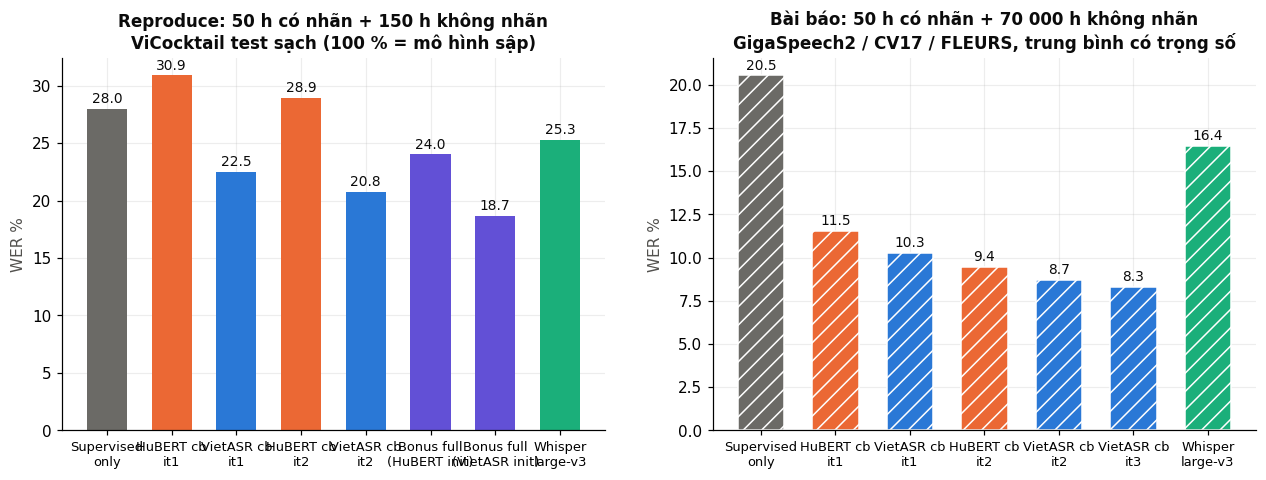

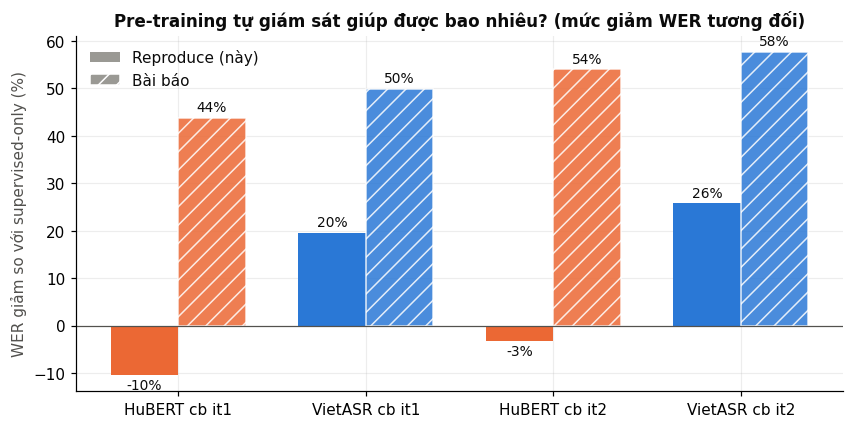

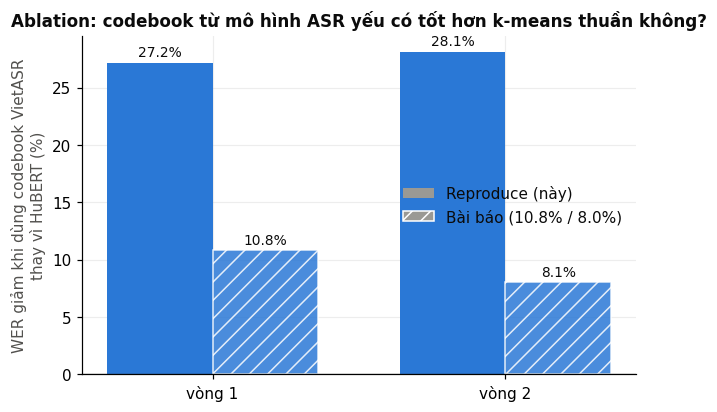

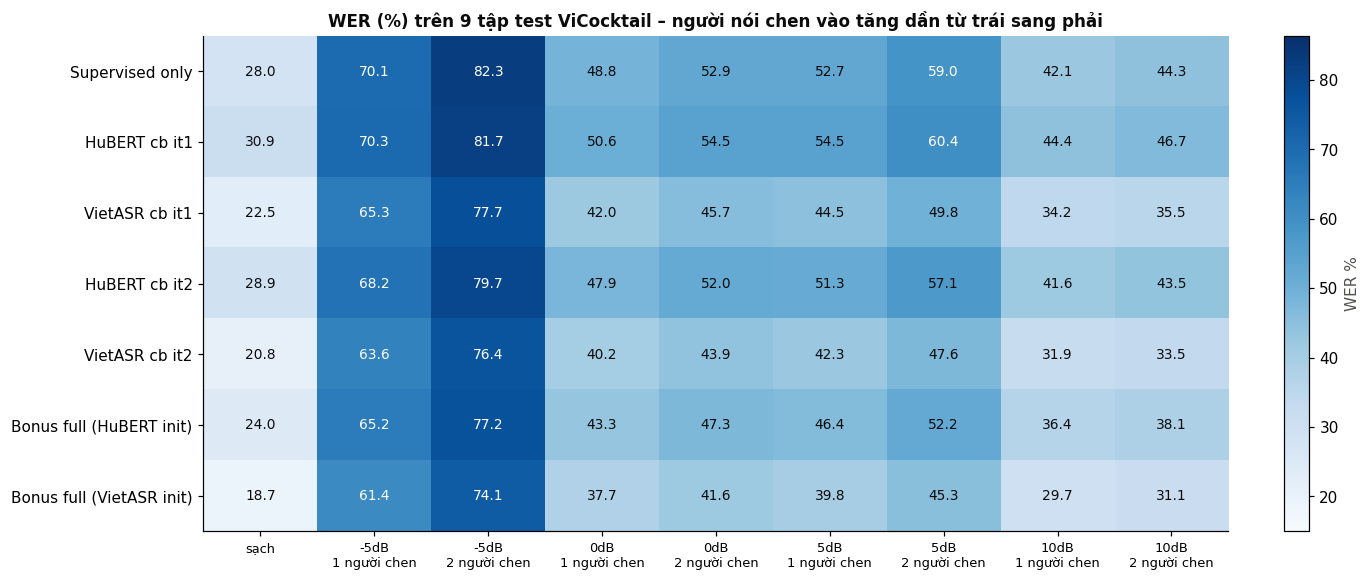

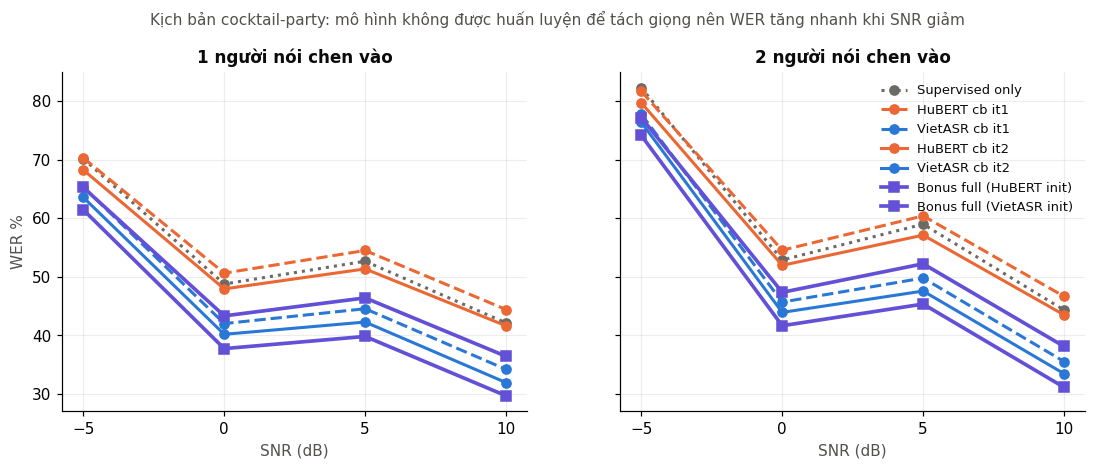

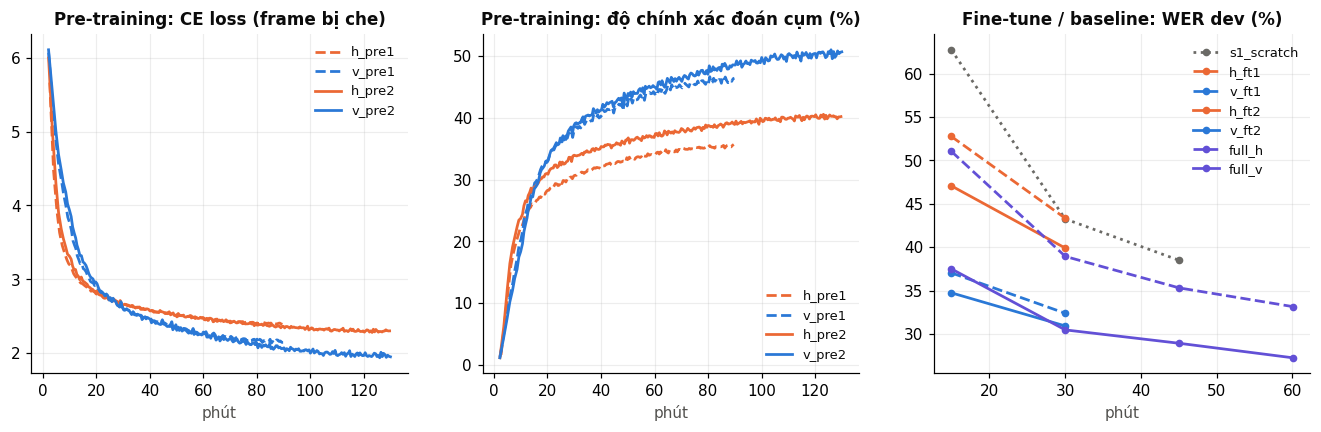

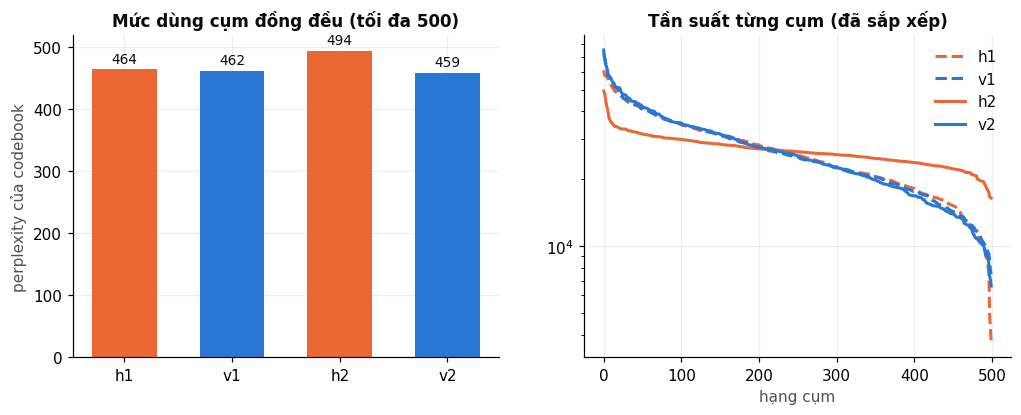

,hệ thống,tham số (M),dev,test sạch,TB 8 tập nhiễu,RTF (GPU),WER bài báo
0,Supervised only,12.8,37.72,28.01,56.51,0.0002,20.54
1,HuBERT cb it1,12.8,40.95,30.91,57.88,0.0002,11.53
2,VietASR cb it1,12.8,31.42,22.51,49.36,0.0002,10.28
3,HuBERT cb it2,12.8,38.32,28.91,55.17,0.0002,9.44
4,VietASR cb it2,12.8,29.63,20.78,47.41,0.0002,8.68
5,Bonus full (HuBERT init) [ngoài bài báo],12.8,33.03,24.03,50.78,0.0002,NaN
6,Bonus full (VietASR init) [ngoài bài báo],12.8,26.77,18.69,45.11,0.0002,NaN
7,Whisper large-v3,1542.0,NaN,25.29,NaN,0.4302,16.44


                         Kết luận của bài báo WER sạch (ours) Kết quả
SSL pre-training giúp (it1 < supervised-only)   22.51 < 28.01   ✓ giữ
             Lặp thêm 1 vòng giúp (it2 < it1)   20.78 < 22.51   ✓ giữ
  Codebook ASR-biased > HuBERT codebook (it1)   22.51 < 30.91   ✓ giữ
  Codebook ASR-biased > HuBERT codebook (it2)   20.78 < 28.91   ✓ giữ

Lưu ý: với dữ liệu nhỏ, chênh lệch vài % giữa hai codebook có thể chỉ là nhiễu; 'không giữ' không có nghĩa là bài báo sai.


In [13]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.22, "axes.axisbelow": True, "figure.dpi": 110, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "text.color": "#0b0b0b", "axes.labelcolor": "#52514e"})
C_V, C_H, C_BASE, C_W, C_B = "#2a78d6", "#eb6834", "#6b6a66", "#1baf7a", "#6250d6"   # VietASR / HuBERT / baseline / Whisper / bonus
PAPER = {"scratch": 20.54, "h1": 11.53, "v1": 10.28, "h2": 9.44, "v2": 8.68, "v3": 8.31, "whisper": 16.44}
SYS = [("s1_scratch", "Supervised\nonly", "scratch", C_BASE), ("h_ft1", "HuBERT cb\nit1", "h1", C_H), ("v_ft1", "VietASR cb\nit1", "v1", C_V),
       ("h_ft2", "HuBERT cb\nit2", "h2", C_H), ("v_ft2", "VietASR cb\nit2", "v2", C_V)]
BONUS = [("full_h", "Bonus full\n(HuBERT init)", C_B), ("full_v", "Bonus full\n(VietASR init)", C_B)]
SETS = ["test"] + [f"test_snr_{s}_interferer_{k}" for s in ("n5", "0", "5", "10") for k in (1, 2)]
SET_LABEL = {"test": "sạch", **{f"test_snr_{s}_interferer_{k}": f"{s.replace('n', '-')}dB\n{k} người chen" for s in ("n5", "0", "5", "10") for k in (1, 2)}}
load = lambda p: json.load(open(p)) if Path(p).exists() else None
R = {n: load(RES / f"{n}.json") for n in [x[0] for x in SYS] + [x[0] for x in BONUS]}
R = {k: v for k, v in R.items() if v}
WH = load(RES / "whisper_large_v3.json")
alive = lambda n: n in R and R[n]["wer"].get("test", 999) < 85          # bỏ mô hình đã sập khỏi biểu đồ tương đối
clean = lambda n: R[n]["wer"].get("test", np.nan)
save = lambda fig, name: (fig.savefig(RES / name, dpi=140, bbox_inches="tight"), plt.show())

def bar_labels(ax, bars, fmt="{:.1f}"):
    for b in bars:
        h = b.get_height()
        ax.annotate(fmt.format(h), (b.get_x() + b.get_width() / 2, h), ha="center", va="bottom" if h >= 0 else "top",
                    xytext=(0, 2 if h >= 0 else -2), textcoords="offset points", fontsize=9, color="#0b0b0b")

# ---------- Fig 1: WER tuyệt đối ----------
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
items = [(n, l, col) for n, l, _, col in SYS if n in R] + [(n, l, col) for n, l, col in BONUS if n in R]
bars = ax[0].bar(range(len(items)), [clean(n) for n, _, _ in items], color=[c_ for _, _, c_ in items], width=0.62)
bar_labels(ax[0], bars)
labels = [l for _, l, _ in items]
if WH and "test" in WH["wer"]:
    b = ax[0].bar(len(items), WH["wer"]["test"], color=C_W, width=0.62); bar_labels(ax[0], b); labels.append("Whisper\nlarge-v3")
ax[0].set_xticks(range(len(labels))); ax[0].set_xticklabels(labels, fontsize=8.5); ax[0].set_ylabel("WER %")
ax[0].set_title(f"Reproduce: {LAB_HOURS} h có nhãn + {UNL_HOURS} h không nhãn\nViCocktail test sạch (100 % = mô hình sập)")
pk = ["scratch", "h1", "v1", "h2", "v2", "v3", "whisper"]
pl = ["Supervised\nonly", "HuBERT cb\nit1", "VietASR cb\nit1", "HuBERT cb\nit2", "VietASR cb\nit2", "VietASR cb\nit3", "Whisper\nlarge-v3"]
pc = [C_BASE, C_H, C_V, C_H, C_V, C_V, C_W]
b = ax[1].bar(range(len(pk)), [PAPER[k] for k in pk], color=pc, width=0.62, hatch="//", edgecolor="white")
bar_labels(ax[1], b); ax[1].set_xticks(range(len(pk))); ax[1].set_xticklabels(pl, fontsize=8.5); ax[1].set_ylabel("WER %")
ax[1].set_title("Bài báo: 50 h có nhãn + 70 000 h không nhãn\nGigaSpeech2 / CV17 / FLEURS, trung bình có trọng số")
save(fig, "fig1_absolute_wer.png")

# ---------- Fig 2: mức giảm tương đối so với supervised-only ----------
if alive("s1_scratch"):
    keys = [("h_ft1", "h1", "HuBERT cb it1", C_H), ("v_ft1", "v1", "VietASR cb it1", C_V), ("h_ft2", "h2", "HuBERT cb it2", C_H), ("v_ft2", "v2", "VietASR cb it2", C_V)]
    keys = [k for k in keys if alive(k[0])]
    ours = [100 * (1 - clean(n) / clean("s1_scratch")) for n, *_ in keys]
    paper = [100 * (1 - PAPER[p] / PAPER["scratch"]) for _, p, *_ in keys]
    x = np.arange(len(keys)); w = 0.36
    fig, ax = plt.subplots(figsize=(9, 4.2))
    b1 = ax.bar(x - w / 2, ours, w, color=[k[3] for k in keys]); b2 = ax.bar(x + w / 2, paper, w, color=[k[3] for k in keys], hatch="//", edgecolor="white", alpha=0.85)
    bar_labels(ax, b1, "{:.0f}%"); bar_labels(ax, b2, "{:.0f}%")
    ax.set_xticks(x); ax.set_xticklabels([k[2] for k in keys]); ax.set_ylabel("WER giảm so với supervised-only (%)"); ax.axhline(0, color="#52514e", lw=0.8)
    ax.legend(handles=[Patch(facecolor="#9a9994", label="Reproduce (này)"), Patch(facecolor="#9a9994", hatch="//", edgecolor="white", label="Bài báo")], frameon=False, loc="upper left")
    ax.set_title("Pre-training tự giám sát giúp được bao nhiêu? (mức giảm WER tương đối)")
    save(fig, "fig2_relative_gain.png")
else:
    print("Fig 2 bỏ qua: không có baseline supervised-only còn sống (S1 sập / dùng kế hoạch B).")

# ---------- Fig 3: codebook ASR-biased vs HuBERT ----------
rows = []
for it, (h, v, ph, pv) in enumerate([("h_ft1", "v_ft1", "h1", "v1"), ("h_ft2", "v_ft2", "h2", "v2")], 1):
    if alive(h) and alive(v):
        rows.append((f"vòng {it}", 100 * (clean(h) - clean(v)) / clean(h), 100 * (PAPER[ph] - PAPER[pv]) / PAPER[ph]))
if rows:
    fig, ax = plt.subplots(figsize=(6.5, 4))
    x = np.arange(len(rows)); w = 0.36
    b1 = ax.bar(x - w / 2, [r[1] for r in rows], w, color=C_V); b2 = ax.bar(x + w / 2, [r[2] for r in rows], w, color=C_V, hatch="//", edgecolor="white", alpha=0.85)
    bar_labels(ax, b1, "{:.1f}%"); bar_labels(ax, b2, "{:.1f}%")
    ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rows]); ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_ylabel("WER giảm khi dùng codebook VietASR\nthay vì HuBERT (%)")
    ax.legend(handles=[Patch(facecolor="#9a9994", label="Reproduce (này)"), Patch(facecolor="#9a9994", hatch="//", edgecolor="white", label="Bài báo (10.8% / 8.0%)")], frameon=False)
    ax.set_title("Ablation: codebook từ mô hình ASR yếu có tốt hơn k-means thuần không?")
    save(fig, "fig3_codebook_ablation.png")

# ---------- Fig 4: heatmap 9 tập test ----------
allm = [(n, l.replace("\n", " ")) for n, l, *_ in SYS if n in R] + [(n, l.replace("\n", " ")) for n, l, _ in BONUS if n in R]
M_ = np.array([[R[n]["wer"].get(s, np.nan) for s in SETS] for n, _ in allm])
fig, ax = plt.subplots(figsize=(13, 0.55 * len(allm) + 2))
lo, hi = np.nanmin(M_) * 0.8, min(np.nanmax(M_) * 1.05, 105)
im = ax.imshow(np.minimum(M_, hi), cmap="Blues", aspect="auto", vmin=lo, vmax=hi)
ax.grid(False); ax.set_xticks(range(len(SETS))); ax.set_xticklabels([SET_LABEL[s] for s in SETS], fontsize=8.5)
ax.set_yticks(range(len(allm))); ax.set_yticklabels([l for _, l in allm])
thr = lo + 0.6 * (hi - lo)
for i in range(M_.shape[0]):
    for j in range(M_.shape[1]):
        if not np.isnan(M_[i, j]): ax.text(j, i, f"{M_[i, j]:.1f}", ha="center", va="center", color="white" if M_[i, j] > thr else "#0b0b0b", fontsize=9)
ax.set_title("WER (%) trên 9 tập test ViCocktail – người nói chen vào tăng dần từ trái sang phải"); fig.colorbar(im, ax=ax, fraction=0.025, label="WER %")
save(fig, "fig4_heatmap.png")

# ---------- Fig 5: độ bền theo SNR ----------
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
snr = [("n5", -5), ("0", 0), ("5", 5), ("10", 10)]
sty = {"scratch": ":", "h1": "--", "v1": "--", "h2": "-", "v2": "-"}
for k, ax in zip((1, 2), axs):
    for (n, lab, pk_, col) in SYS:
        if alive(n):
            ax.plot([s[1] for s in snr], [R[n]["wer"].get(f"test_snr_{s[0]}_interferer_{k}", np.nan) for s in snr], sty[pk_], color=col, marker="o", ms=6, lw=2, label=lab.replace("\n", " "))
    for n, lab, col in BONUS:
        if alive(n):
            ax.plot([s[1] for s in snr], [R[n]["wer"].get(f"test_snr_{s[0]}_interferer_{k}", np.nan) for s in snr], "-", color=col, marker="s", ms=6, lw=2.4, label=lab.replace("\n", " "))
    ax.set_xticks([s[1] for s in snr]); ax.set_xlabel("SNR (dB)"); ax.set_title(f"{k} người nói chen vào")
axs[0].set_ylabel("WER %"); axs[1].legend(frameon=False, fontsize=8.5, loc="upper right")
fig.suptitle("Kịch bản cocktail-party: mô hình không được huấn luyện để tách giọng nên WER tăng nhanh khi SNR giảm", y=1.02, fontsize=10, color="#52514e")
save(fig, "fig5_robustness.png")

# ---------- Fig 6: đường huấn luyện ----------
def jl(name):
    f = EXP / name / "log.jsonl"
    return [json.loads(l) for l in open(f)] if f.exists() else []
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for n, col, ls in (("h_pre1", C_H, "--"), ("v_pre1", C_V, "--"), ("h_pre2", C_H, "-"), ("v_pre2", C_V, "-")):
    L = [r for r in jl(n) if "loss" in r]
    if L:
        axs[0].plot([r["min"] for r in L], [r["loss"] for r in L], ls, color=col, lw=1.8, label=n)
        if "acc" in L[0]: axs[1].plot([r["min"] for r in L], [100 * r["acc"] for r in L], ls, color=col, lw=1.8, label=n)
axs[0].set_title("Pre-training: CE loss (frame bị che)"); axs[1].set_title("Pre-training: độ chính xác đoán cụm (%)")
for ax in axs[:2]: ax.set_xlabel("phút"); ax.legend(frameon=False, fontsize=8.5)
for n, col, ls in (("s1_scratch", C_BASE, ":"), ("h_ft1", C_H, "--"), ("v_ft1", C_V, "--"), ("h_ft2", C_H, "-"), ("v_ft2", C_V, "-"), ("full_h", C_B, "--"), ("full_v", C_B, "-")):
    L = [r for r in jl(n) if "dev_wer" in r]
    if L: axs[2].plot([r["min"] for r in L], [r["dev_wer"] for r in L], ls, color=col, marker="o", ms=4, lw=1.8, label=n)
axs[2].set_title("Fine-tune / baseline: WER dev (%)"); axs[2].set_xlabel("phút"); axs[2].legend(frameon=False, fontsize=8.5)
save(fig, "fig6_training_curves.png")

# ---------- Fig 7: sức khoẻ codebook ----------
cb = {n: load(WORK / f"labels_{n}.json") for n in ("h1", "v1", "h2", "v2")}
cb = {k: v for k, v in cb.items() if v}
if cb:
    cols = {"h1": C_H, "h2": C_H, "v1": C_V, "v2": C_V}; st_ = {"h1": "--", "v1": "--", "h2": "-", "v2": "-"}
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
    bars = axs[0].bar(range(len(cb)), [v["perplexity"] for v in cb.values()], color=[cols[k] for k in cb], width=0.6)
    bar_labels(axs[0], bars, "{:.0f}"); axs[0].set_xticks(range(len(cb))); axs[0].set_xticklabels(list(cb)); axs[0].set_ylabel("perplexity của codebook"); axs[0].set_title(f"Mức dùng cụm đồng đều (tối đa {N_CLUSTERS})")
    for k, v in cb.items(): axs[1].semilogy(np.sort(np.array(v["hist"]) + 1)[::-1], st_[k], color=cols[k], lw=2, label=k)
    axs[1].set_title("Tần suất từng cụm (đã sắp xếp)"); axs[1].set_xlabel("hạng cụm"); axs[1].legend(frameon=False)
    save(fig, "fig7_codebooks.png")

# ---------- bảng tổng hợp ----------
tab = []
for (n, lab, pk_, _) in SYS:
    if n in R:
        r = R[n]; noisy = [r["wer"][s] for s in SETS[1:] if s in r["wer"]]
        tab.append({"hệ thống": lab.replace("\n", " "), "tham số (M)": round(r["params_M"], 1), "dev": round(r["wer"].get("dev", np.nan), 2), "test sạch": round(clean(n), 2),
                    "TB 8 tập nhiễu": round(float(np.mean(noisy)), 2) if noisy else np.nan, "RTF (GPU)": round(r["rtf"], 4), "WER bài báo": PAPER[pk_]})
for n, lab, _ in BONUS:
    if n in R:
        r = R[n]; noisy = [r["wer"][s] for s in SETS[1:] if s in r["wer"]]
        tab.append({"hệ thống": lab.replace("\n", " ") + " [ngoài bài báo]", "tham số (M)": round(r["params_M"], 1), "dev": round(r["wer"].get("dev", np.nan), 2), "test sạch": round(clean(n), 2),
                    "TB 8 tập nhiễu": round(float(np.mean(noisy)), 2) if noisy else np.nan, "RTF (GPU)": round(r["rtf"], 4), "WER bài báo": np.nan})
if WH:
    tab.append({"hệ thống": "Whisper large-v3", "tham số (M)": 1542, "dev": np.nan, "test sạch": round(WH["wer"].get("test", np.nan), 2),
                "TB 8 tập nhiễu": np.nan, "RTF (GPU)": round(WH["rtf"], 4), "WER bài báo": PAPER["whisper"]})
df = pd.DataFrame(tab); df.to_csv(RES / "summary.csv", index=False); display(df)

# ---------- các kết luận của bài báo có giữ không? ----------
chk = []
def claim(text, a, b):
    if alive(a) and alive(b):
        chk.append((text, f"{clean(a):.2f} < {clean(b):.2f}", "✓ giữ" if clean(a) < clean(b) else "✗ không giữ"))
claim("SSL pre-training giúp (it1 < supervised-only)", "v_ft1", "s1_scratch")
claim("Lặp thêm 1 vòng giúp (it2 < it1)", "v_ft2", "v_ft1")
claim("Codebook ASR-biased > HuBERT codebook (it1)", "v_ft1", "h_ft1")
claim("Codebook ASR-biased > HuBERT codebook (it2)", "v_ft2", "h_ft2")
print(pd.DataFrame(chk, columns=["Kết luận của bài báo", "WER sạch (ours)", "Kết quả"]).to_string(index=False) if chk else "Chưa đủ mô hình còn sống để kiểm tra các kết luận.")
print("\nLưu ý: với dữ liệu nhỏ, chênh lệch vài % giữa hai codebook có thể chỉ là nhiễu; 'không giữ' không có nghĩa là bài báo sai.")